# Smoking & Health Time-Series Analysis — BRFSS (1995–2010)

**Project context:** Explore changes in adult tobacco-use prevalence in the United States using the provided CDC BRFSS four-level smoking dataset, then compare classical and automated forecasting methods.

This notebook is designed for **Google Colab**. It includes data inspection, cleaning, EDA, stationarity tests, parameter rationale, chronological holdout evaluation, forecast comparison, and domain interpretation.

> **Important data limitation:** This file contains annual state-level prevalence columns for four smoking-status categories. It does not contain individual-level health outcomes (e.g., disease diagnoses), and 1995–2010 provides only 16 annual points per national aggregate. Results are exploratory and should not be interpreted as causal or as clinical risk estimates. Annual data do not support within-year seasonality analysis.

## 1. Setup and load the supplied CSV

In [ ]:
!pip -q install statsmodels scikit-learn matplotlib seaborn prophet autots

In [ ]:
import warnings, sys, subprocess, importlib.util
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.api import VAR

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

from google.colab import files
uploaded = files.upload()
csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_name is None:
    raise ValueError("Please upload the provided BRFSS CSV file.")
df_raw = pd.read_csv(csv_name)
print("Shape:", df_raw.shape)
display(df_raw.head())
print(df_raw.info())

Saving brfss-prevalence-and-trends-data-tobacco-use-four-level-smoking-data-for-1995-2010.csv to brfss-prevalence-and-trends-data-tobacco-use-four-level-smoking-data-for-1995-2010.csv
Shape: (876, 9)


,Year,State,Smoke everyday,Smoke some days,Former smoker,Never smoked,Location 1,Counties,States
0,2010,Alabama,15.6,6.3,23.9,54.2,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0
1,2010,Alaska,13.5,6.8,26.1,53.6,"{'latitude': '64.84507999974238', 'longitude':...",1673.0,51.0
2,2010,Arizona,10.7,4.4,27.9,57.1,"{'latitude': '34.86596999961597', 'longitude':...",986.0,7.0
3,2010,Arkansas,17.3,5.6,24.1,53.0,"{'latitude': '34.748649999697875', 'longitude'...",998.0,15.0
4,2010,California,7.5,4.6,23.1,64.8,"{'latitude': '37.638300000444815', 'longitude'...",1340.0,8.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 876 entries, 0 to 875
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             876 non-null    int64  
 1   State            876 non-null    object 
 2   Smoke everyday   876 non-null    float64
 3   Smoke some days  876 non-null    float64
 4   Former smoker    876 non-null    float64
 5   Never smoked     876 non-null    float64
 6   Location 1       839 non-null    object 
 7   Counties         812 non-null    float64
 8   States           812 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 61.7+ KB
None


## 2. Dataset inspection and cleaning

Expected fields: `Year`, `State`, four smoking-status prevalence columns, `Location 1`, `Counties`, and `States`. Non-numeric location identifiers are not used as model inputs. We preserve state-level rows for subgroup exploration and create a national annual series by averaging state prevalence values. This is an **unweighted state average**, not a population-weighted national prevalence estimate.

In [ ]:
print("Columns:", df_raw.columns.tolist())
display(df_raw.describe(include="all").T)
print("\\nMissing values:")
display(df_raw.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df_raw.duplicated().sum())

Columns: ['Year', 'State', 'Smoke everyday', 'Smoke some days', 'Former smoker', 'Never smoked', 'Location 1', 'Counties', 'States']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,876.0,NaN,NaN,NaN,2002.591324,4.593622,1995.0,1999.0,2003.0,2007.0,2010.0
State,876,56,Alabama,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoke everyday,876.0,NaN,NaN,NaN,16.555479,3.981661,3.6,13.9,16.7,19.1,29.1
Smoke some days,876.0,NaN,NaN,NaN,4.839498,1.156771,1.3,4.2,4.9,5.525,8.5
Former smoker,876.0,NaN,NaN,NaN,24.321918,3.501092,9.9,22.9,24.5,26.2,33.4
Never smoked,876.0,NaN,NaN,NaN,54.257306,5.603022,39.5,51.075,53.5,56.2,83.7
Location 1,839,55,"{'latitude': '32.840569999605975', 'longitude'...",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Counties,812.0,NaN,NaN,NaN,1601.958128,908.311992,94.0,712.0,1673.0,2405.0,3218.0
States,812.0,NaN,NaN,NaN,26.036946,14.71693,1.0,13.0,26.0,39.0,51.0


\nMissing values:


,missing_count
Year,0
State,0
Smoke everyday,0
Smoke some days,0
Former smoker,0
Never smoked,0
Location 1,37
Counties,64
States,64


Duplicate rows: 0


In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

smoking_cols = ["Smoke everyday", "Smoke some days", "Former smoker", "Never smoked"]
for col in smoking_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Year"])
df["Year"] = df["Year"].astype(int)
df = df.drop_duplicates()

for col in smoking_cols:
    df.loc[~df[col].between(0, 100), col] = np.nan

print("Cleaned shape:", df.shape)
display(df[["Year", "State"] + smoking_cols].isna().sum().to_frame("missing_after_checks"))

Cleaned shape: (876, 9)


,missing_after_checks
Year,0
State,0
Smoke everyday,0
Smoke some days,0
Former smoker,0
Never smoked,0


### Missing values

In [ ]:
df = df.sort_values(["State", "Year"])
for col in smoking_cols:
    df[col] = df.groupby("State", dropna=False)[col].transform(
        lambda s: s.interpolate(limit_direction="both")
    )
    df[col] = df[col].fillna(df[col].median())

print("Remaining missing smoking values:", int(df[smoking_cols].isna().sum().sum()))

Remaining missing smoking values: 0


## 3. Exploratory Data Analysis (EDA)

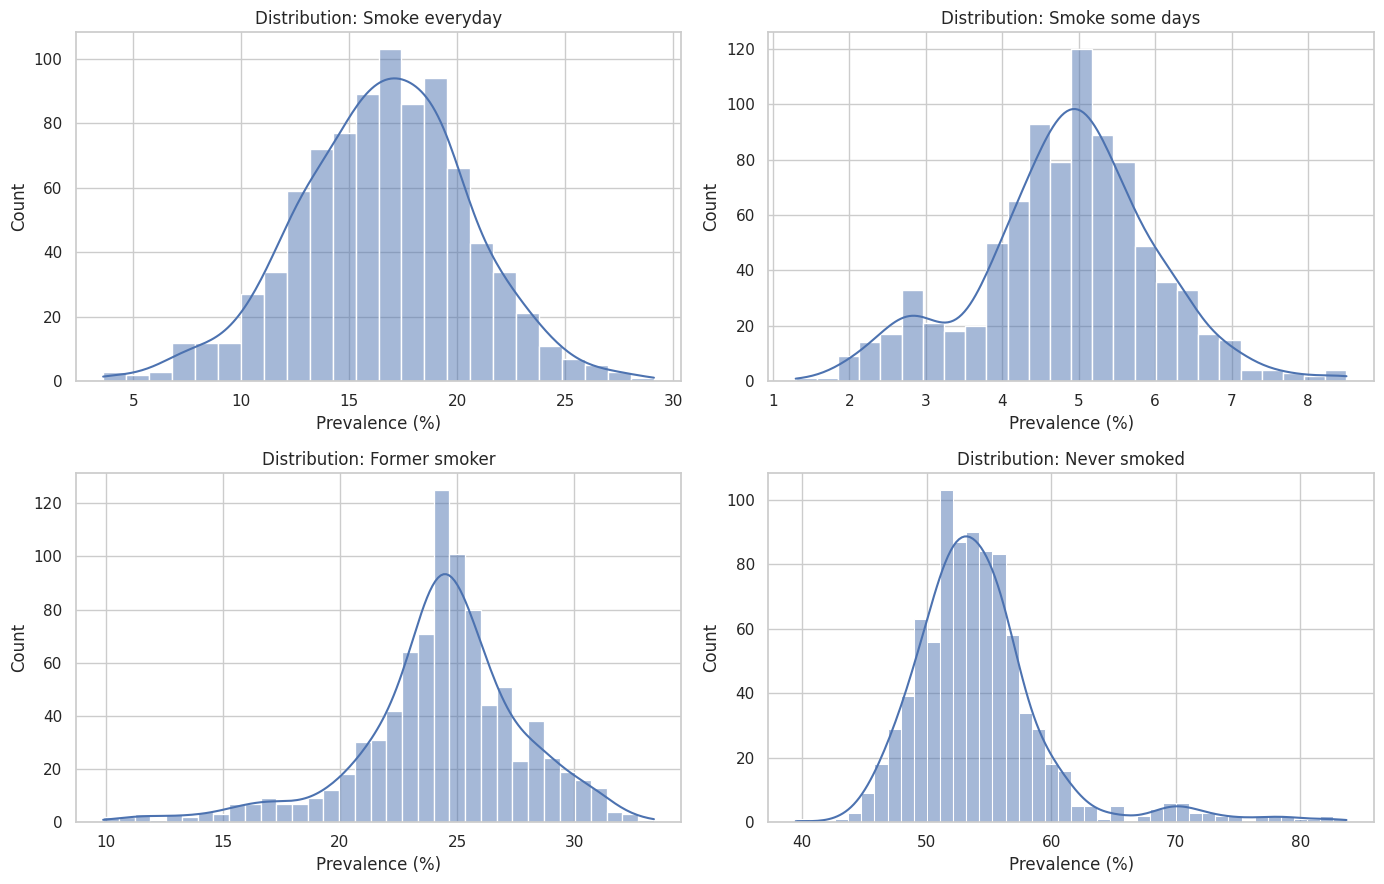

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, ax in zip(smoking_cols, axes.flat):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel("Prevalence (%)")
plt.tight_layout()
plt.show()

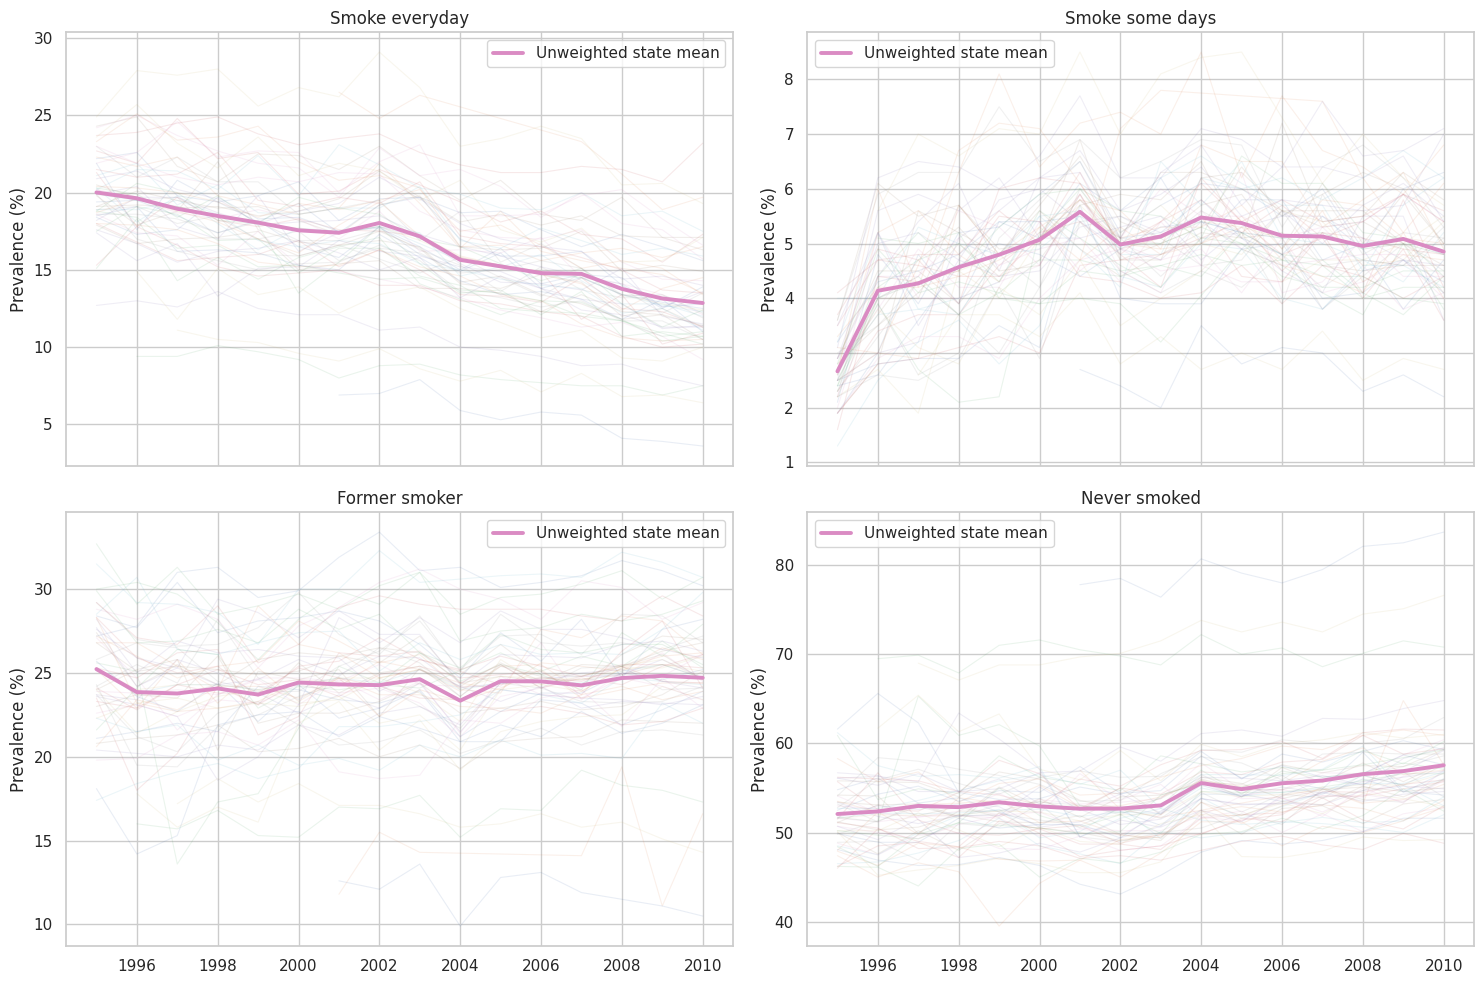

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
for col, ax in zip(smoking_cols, axes.flat):
    for state, part in df.groupby("State"):
        ax.plot(part["Year"], part[col], alpha=0.12, linewidth=0.8)
    yearly_mean = df.groupby("Year")[col].mean()
    ax.plot(yearly_mean.index, yearly_mean.values, linewidth=2.8, label="Unweighted state mean")
    ax.set_title(col)
    ax.set_ylabel("Prevalence (%)")
    ax.legend()
plt.tight_layout()
plt.show()

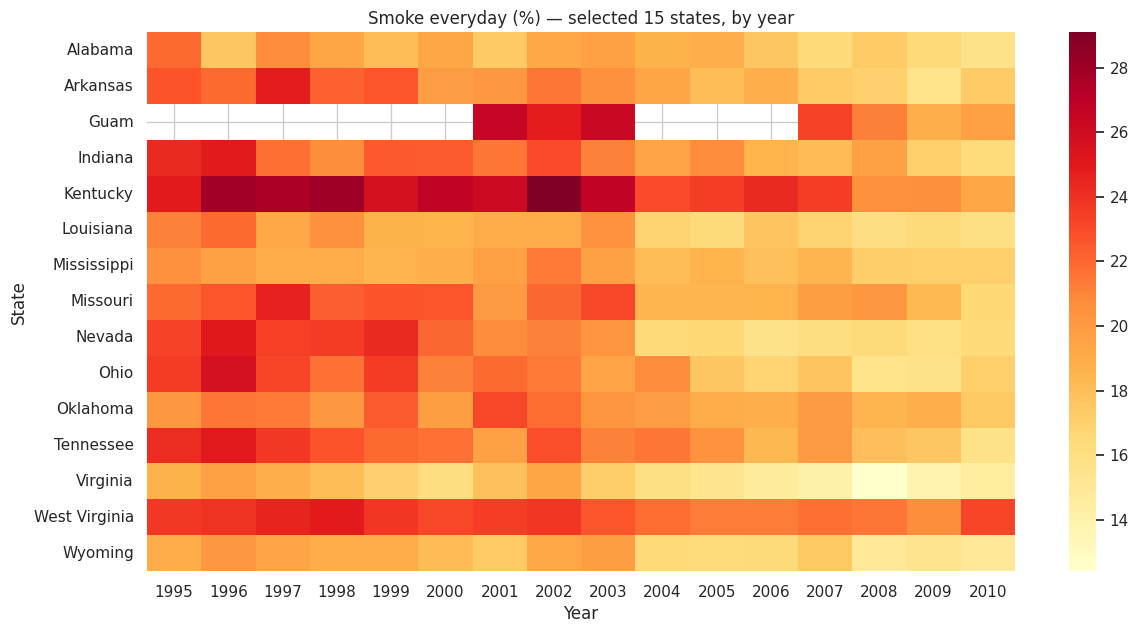

In [ ]:
latest_year = df["Year"].max()
selected_states = (df[df["Year"] == latest_year]
                   .sort_values("Smoke everyday", ascending=False)["State"].head(15).tolist())
heat = df[df["State"].isin(selected_states)].pivot_table(
    index="State", columns="Year", values="Smoke everyday", aggfunc="mean"
)
plt.figure(figsize=(14, 7))
sns.heatmap(heat, cmap="YlOrRd", annot=False)
plt.title("Smoke everyday (%) — selected 15 states, by year")
plt.xlabel("Year")
plt.ylabel("State")
plt.show()

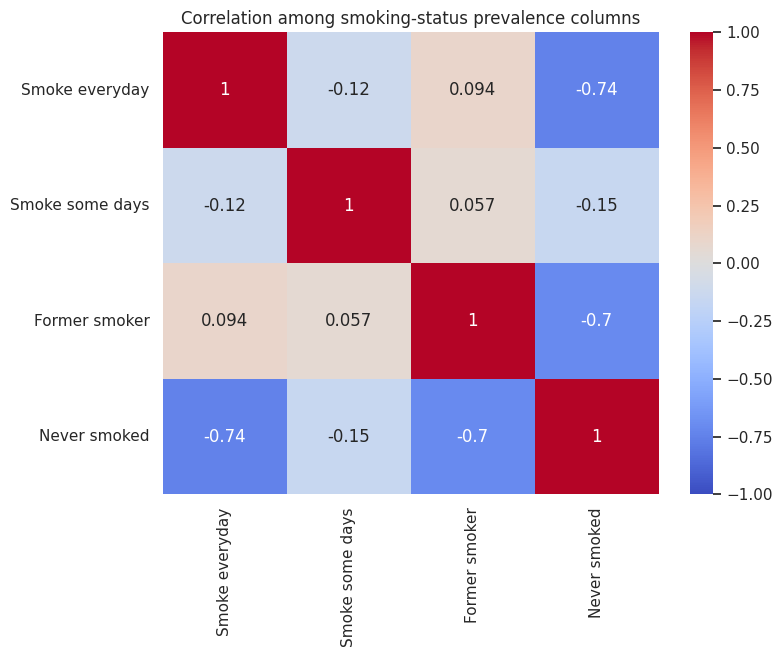

,variable,lower_IQR_bound,upper_IQR_bound,potential_outliers
0,Smoke everyday,6.1000,26.9000,11
1,Smoke some days,2.2125,7.5125,28
2,Former smoker,17.9500,31.1500,62
3,Never smoked,43.3875,63.8875,47


In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[smoking_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation among smoking-status prevalence columns")
plt.show()

anomaly_rows = []
for col in smoking_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomaly_rows.append({"variable": col, "lower_IQR_bound": lo, "upper_IQR_bound": hi,
                         "potential_outliers": int(((df[col] < lo) | (df[col] > hi)).sum())})
display(pd.DataFrame(anomaly_rows))

## 4. Create a modeling series and inspect stationarity

The target is `Smoke everyday`, averaged across states for each year. The data are annual, so a seasonal cycle is not automatically assumed. The chronological final four years are reserved as a test set; no random shuffling is used.

ADF null hypothesis: the series has a unit root (non-stationary).  
KPSS null hypothesis: the series is level-stationary.  
The tests can disagree; interpret them alongside the plot and domain context.

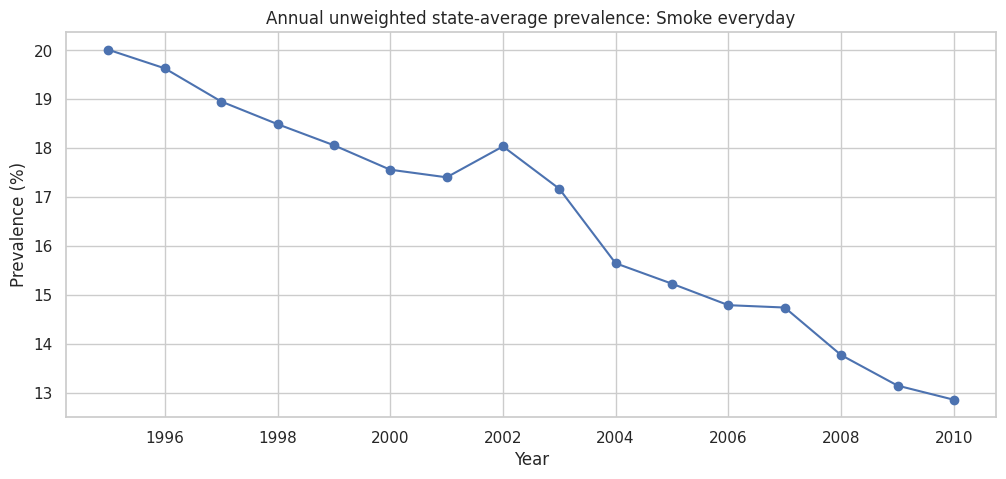

--- Original target ---
ADF statistic: 12.6532, p-value: 1.0000
KPSS statistic: 0.6327, p-value: 0.0197
--- First difference ---
ADF statistic: -3.7841, p-value: 0.0031
KPSS statistic: 0.0674, p-value: 0.1000


/tmp/ipykernel_1989/3767504074.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(s, regression="c", nlags="auto")


In [ ]:
annual = df.groupby("Year")[smoking_cols].mean().sort_index()
annual.index = pd.to_datetime(annual.index.astype(str), format="%Y")
annual.index.name = "Date"
target_name = "Smoke everyday"
y = annual[target_name].astype(float).asfreq("YS")

plt.figure(figsize=(12, 5))
plt.plot(y, marker="o")
plt.title("Annual unweighted state-average prevalence: Smoke everyday")
plt.ylabel("Prevalence (%)")
plt.xlabel("Year")
plt.show()

def stationarity_tests(series, label="series"):
    s = pd.Series(series).dropna()
    print(f"--- {label} ---")
    adf_result = adfuller(s, autolag="AIC")
    print(f"ADF statistic: {adf_result[0]:.4f}, p-value: {adf_result[1]:.4f}")
    try:
        kpss_result = kpss(s, regression="c", nlags="auto")
        print(f"KPSS statistic: {kpss_result[0]:.4f}, p-value: {kpss_result[1]:.4f}")
    except Exception as e:
        print("KPSS could not be calculated:", e)

stationarity_tests(y, "Original target")
stationarity_tests(y.diff().dropna(), "First difference")

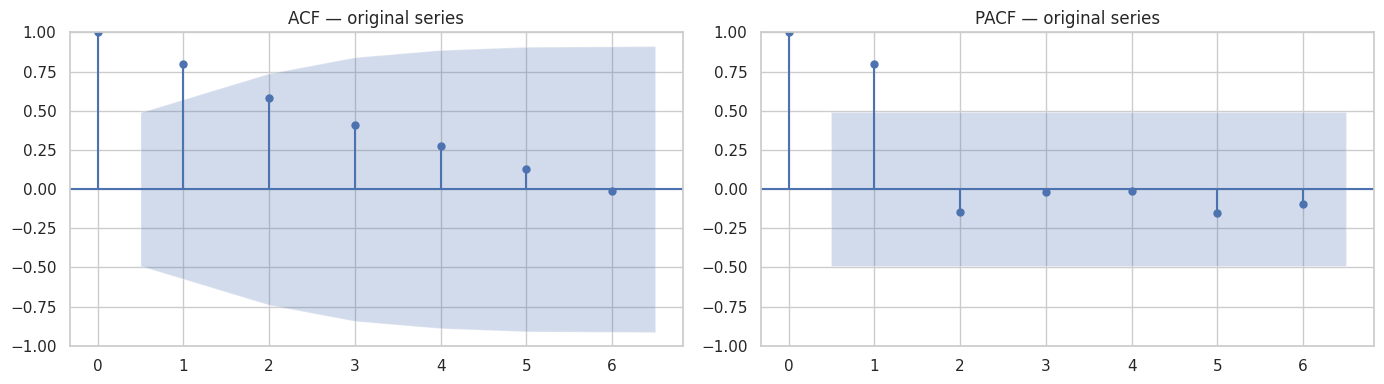

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y.dropna(), lags=min(6, len(y.dropna())-1), ax=axes[0])
plot_pacf(y.dropna(), lags=min(6, len(y.dropna())//2-1), method="ywm", ax=axes[1])
axes[0].set_title("ACF — original series")
axes[1].set_title("PACF — original series")
plt.tight_layout()
plt.show()

## 5. Train/test split and evaluation metrics

Four years are held out. With such a short history, model ranking is uncertain; the table should be read as a comparison on this particular holdout, not proof that one model is universally best. MAPE can be unstable when actual values are near zero; this target is normally well above zero, but MAE and RMSE remain important.

In [ ]:
test_size = min(4, max(2, len(y)//4))
train, test = y.iloc[:-test_size], y.iloc[-test_size:]
print("Train:", train.index.min().year, "to", train.index.max().year)
print("Test :", test.index.min().year, "to", test.index.max().year)

def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(np.abs((actual - predicted) / np.where(actual == 0, np.nan, actual))) * 100
    }

results = []
predictions = {}
def record_model(name, forecast):
    forecast = pd.Series(np.asarray(forecast), index=test.index)
    predictions[name] = forecast
    results.append({"Model": name, **metrics(test, forecast)})

Train: 1995 to 2006
Test : 2007 to 2010


## 6. Classical forecasting models

For AR/MA/ARMA, we fit ARIMA with the appropriate `d=0` form to the training series after first-difference stationarity checks. The orders below are modest due to only 12 training observations; they are transparent baseline choices rather than exhaustive optimization.

In [ ]:
try:
    fit = ARIMA(train, order=(1, 0, 0), trend="c").fit()
    record_model("AR(1)", fit.forecast(steps=len(test)))
except Exception as e: print("AR(1) skipped:", e)

try:
    fit = ARIMA(train, order=(0, 0, 1), trend="c").fit()
    record_model("MA(1)", fit.forecast(steps=len(test)))
except Exception as e: print("MA(1) skipped:", e)

try:
    fit = ARIMA(train, order=(1, 0, 1), trend="c").fit()
    record_model("ARMA(1,1)", fit.forecast(steps=len(test)))
except Exception as e: print("ARMA(1,1) skipped:", e)

try:
    fit = ARIMA(train, order=(1, 1, 1), trend="t").fit()
    record_model("ARIMA(1,1,1)", fit.forecast(steps=len(test)))
except Exception as e: print("ARIMA skipped:", e)

try:
    fit = ARIMA(train, order=(1, 1, 1), seasonal_order=(1, 0, 0, 2), trend="t").fit()
    record_model("SARIMA(1,1,1)x(1,0,0,2)", fit.forecast(steps=len(test)))
except Exception as e: print("SARIMA skipped:", e)

try:
    fit = ExponentialSmoothing(train, trend="add", seasonal=None,
                               initialization_method="estimated").fit(optimized=True)
    record_model("Holt-Winters (additive trend)", fit.forecast(len(test)))
except Exception as e: print("Holt-Winters skipped:", e)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


### ARIMAX and SARIMAX

The other smoking-status measures are used as exogenous predictors. For a clean forecast made in practice, future exogenous values must themselves be known or forecast. In this holdout experiment, their observed test-period values are supplied, so ARIMAX/SARIMAX scores are **conditional forecasts** and are not directly comparable to models that use only past target values. This caveat is reported explicitly.

In [ ]:
exog_cols = ["Smoke some days", "Former smoker", "Never smoked"]
X_train = annual.loc[train.index, exog_cols]
X_test = annual.loc[test.index, exog_cols]

try:
    fit = ARIMA(train, exog=X_train, order=(1, 1, 1), trend="t").fit()
    record_model("ARIMAX(1,1,1)", fit.forecast(steps=len(test), exog=X_test))
except Exception as e: print("ARIMAX skipped:", e)

try:
    fit = ARIMA(train, exog=X_train, order=(1, 1, 1),
                seasonal_order=(1, 0, 0, 2), trend="t").fit()
    record_model("SARIMAX(1,1,1)x(1,0,0,2)", fit.forecast(steps=len(test), exog=X_test))
except Exception as e: print("SARIMAX skipped:", e)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred freq

### VARIMA-style multivariate model

Statsmodels provides VAR, but not a direct general VARIMA class. Here we fit a VAR to the **first-differenced** smoking-status measures (a VARIMA-style multivariate differenced model), then invert the differences to obtain level forecasts. Lag 1 is used conservatively because the annual series is short. Treat this as an approximation, and not a full VARIMA implementation.

In [ ]:
try:
    multivariate = annual[smoking_cols].astype(float)
    train_multi = multivariate.iloc[:-test_size]
    test_multi = multivariate.iloc[-test_size:]
    diff_train = train_multi.diff().dropna()
    var_fit = VAR(diff_train).fit(maxlags=1, ic=None, trend="c")
    diff_forecast = var_fit.forecast(diff_train.values[-var_fit.k_ar:], steps=test_size)
    level_forecast = []
    last_level = train_multi.iloc[-1].values.copy()
    for row in diff_forecast:
        last_level = last_level + row
        level_forecast.append(last_level.copy())
    var_target_forecast = pd.Series(
        np.array(level_forecast)[:, smoking_cols.index(target_name)],
        index=test.index
    )
    record_model("Differenced VAR(1) (VARIMA-style)", var_target_forecast)
except Exception as e:
    print("Differenced VAR model skipped:", e)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


## 7. Prophet and AutoTS (automated libraries)

In [ ]:
try:
    from prophet import Prophet
    prophet_train = pd.DataFrame({"ds": train.index, "y": train.values})
    prophet_model = Prophet(yearly_seasonality=False, weekly_seasonality=False,
                            daily_seasonality=False, interval_width=0.80)
    prophet_model.fit(prophet_train)
    future = pd.DataFrame({"ds": test.index})
    prophet_forecast = prophet_model.predict(future)["yhat"].values
    record_model("Prophet (trend only)", prophet_forecast)
except Exception as e:
    print("Prophet skipped. If needed, rerun package installation and restart runtime:", e)

INFO:prophet:n_changepoints greater than number of observations. Using 8.


In [ ]:
try:
    from autots import AutoTS
    autots_train = pd.DataFrame({"Smoke everyday": train.values}, index=train.index)
    auto_model = AutoTS(
        forecast_length=len(test),
        frequency="年",
        prediction_interval=0.90,
        ensemble="simple",
        model_list="fast",
        max_generations=2,
        num_validations=1,
        validation_method="backwards"
    )
    auto_model = auto_model.fit(autots_train)
    auto_prediction = auto_model.predict()
    auto_forecast = auto_prediction.forecast["Smoke everyday"].values
    record_model("AutoTS (fast search)", auto_forecast)
    print("AutoTS best model:", auto_model.best_model_name)
except Exception as e:
    print("AutoTS did not run in this environment. See note below. Error:", e)

Using 1 cpus for n_jobs.
Data frequency is: YS-JAN, used frequency is: 年
AutoTS did not run in this environment. See note below. Error: Invalid frequency: 年, failed to parse with error message: ValueError('last element must be blank')


**Optional Darts / TSFresh extensions:** They are not required to produce the main comparison. Darts has a separate model API and TSFresh is primarily feature extraction; both may require additional dependency setup and, for TSFresh, a sufficiently large set of labeled windows. Since this dataset has only 16 annual time points in the aggregate, adding hundreds of extracted features would risk severe overfitting. Prophet and AutoTS are included above as requested library examples.

## 8. Compare model metrics and plot forecasts

In [ ]:
if not results:
    print("No forecasting models completed. Check installation/runtime errors above.")
else:
    comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
    display(comparison.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "MAPE (%)": "{:.2f}"}))
    comparison.to_csv("forecast_model_comparison.csv", index=False)
    print("Saved comparison table: forecast_model_comparison.csv")

,Model,MAE,RMSE,MAPE (%)
0,"ARIMAX(1,1,1)",0.023,0.024,0.17
1,"SARIMAX(1,1,1)x(1,0,0,2)",0.044,0.046,0.33
2,Prophet (trend only),0.188,0.213,1.36
3,Holt-Winters (additive trend),0.188,0.243,1.34
4,"SARIMA(1,1,1)x(1,0,0,2)",0.189,0.250,1.34
5,"ARIMA(1,1,1)",0.211,0.253,1.51
6,Differenced VAR(1) (VARIMA-style),0.359,0.409,2.59
7,AR(1),1.445,1.672,10.95
8,"ARMA(1,1)",1.458,1.733,11.08
9,MA(1),3.550,3.793,26.61


Saved comparison table: forecast_model_comparison.csv


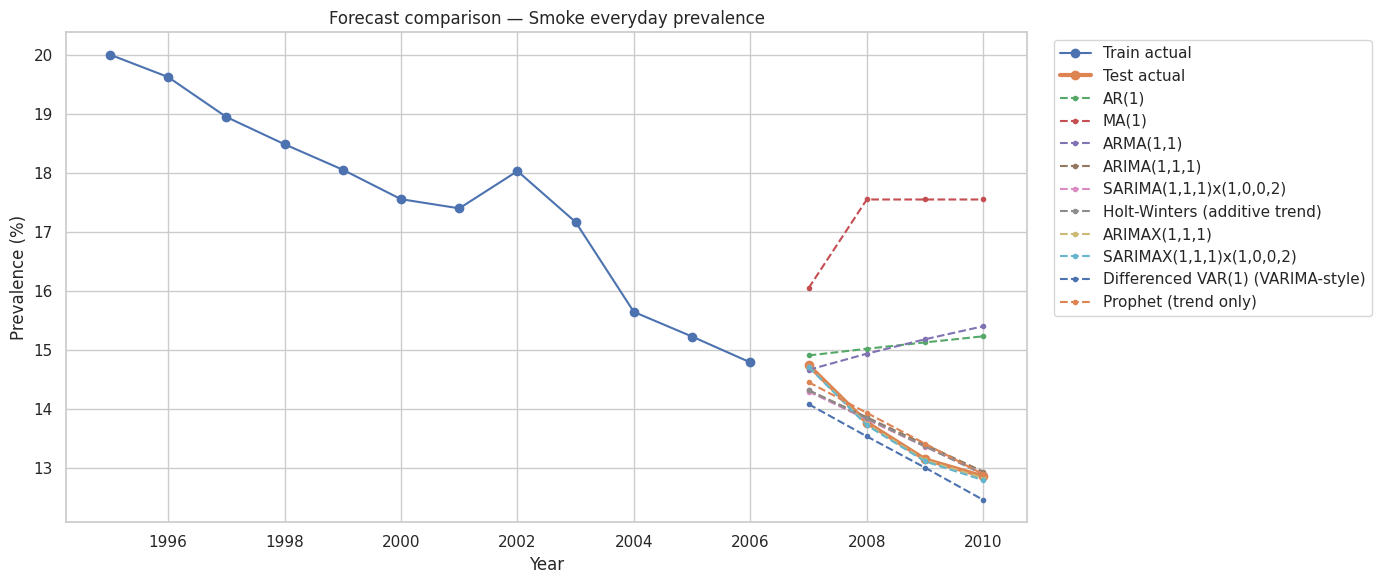

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(train.index, train.values, marker="o", label="Train actual")
plt.plot(test.index, test.values, marker="o", linewidth=3, label="Test actual")
for name, forecast in predictions.items():
    plt.plot(test.index, forecast.values, marker=".", linestyle="--", label=name)
plt.title("Forecast comparison — Smoke everyday prevalence")
plt.ylabel("Prevalence (%)")
plt.xlabel("Year")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

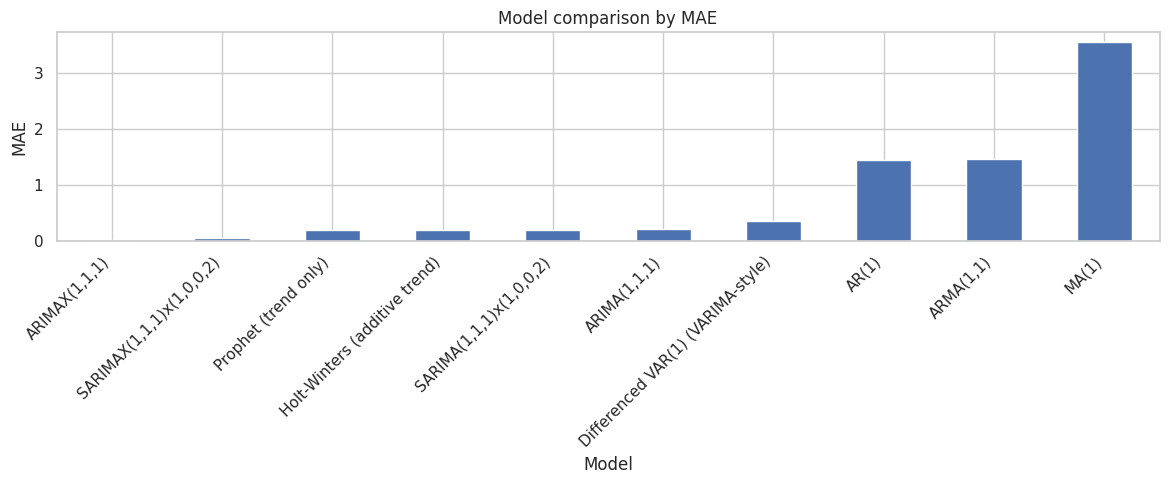

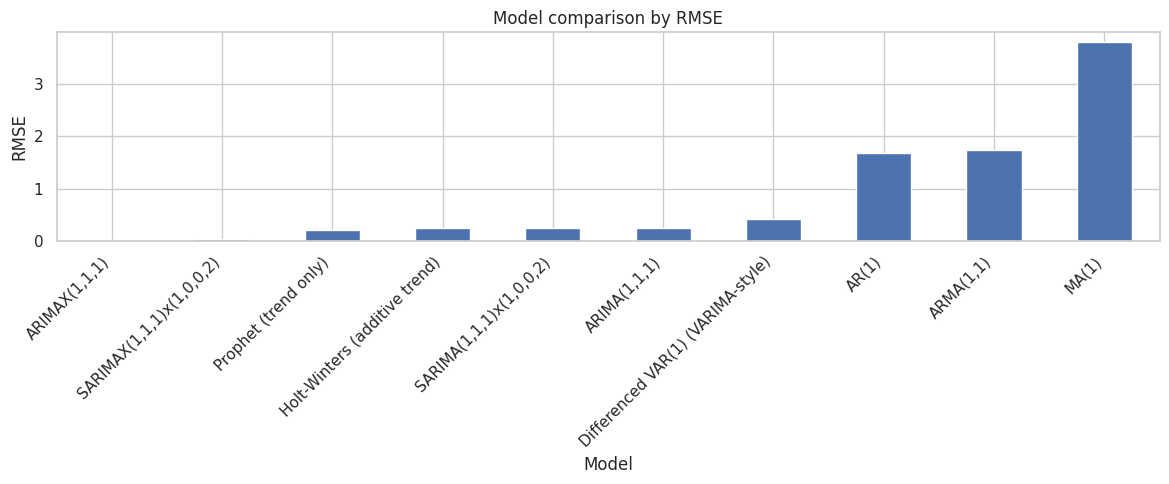

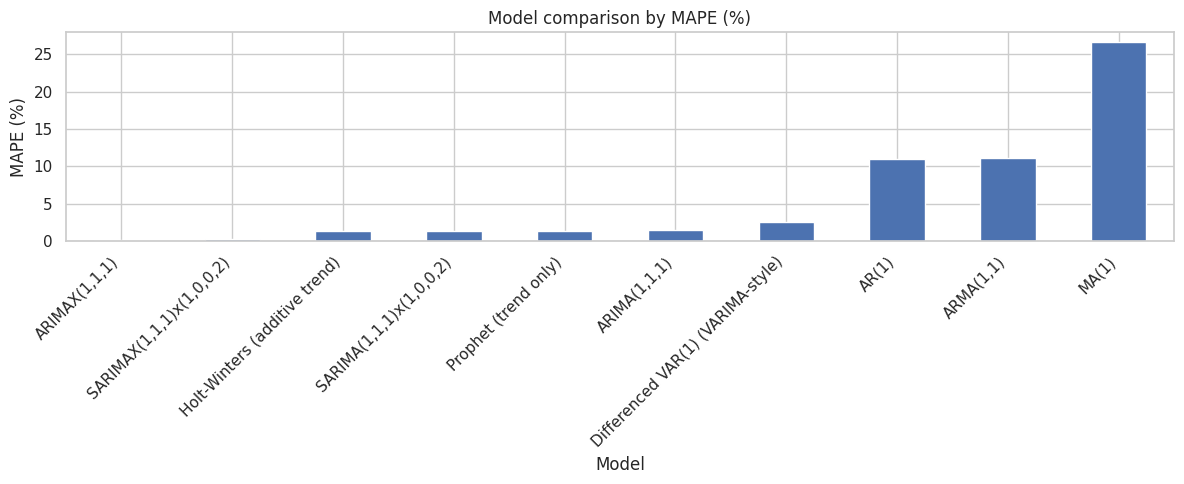

In [ ]:
if results:
    comp = pd.DataFrame(results).set_index("Model")
    for metric in ["MAE", "RMSE", "MAPE (%)"]:
        plt.figure(figsize=(12, 5))
        comp[metric].sort_values().plot(kind="bar")
        plt.title(f"Model comparison by {metric}")
        plt.ylabel(metric)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## 9. Residual diagnostics for a selected model

Select the lowest-RMSE model from this small holdout as a diagnostic example. Residuals should ideally have mean near zero and little remaining autocorrelation. With only four test observations, residual diagnostics and metric ranking are highly limited; for formal diagnostics, inspect fitted training residuals from a selected statsmodels model and consider rolling-origin cross-validation.

Lowest holdout RMSE model: ARIMAX(1,1,1)
Test residual mean: 0.02307658820413927


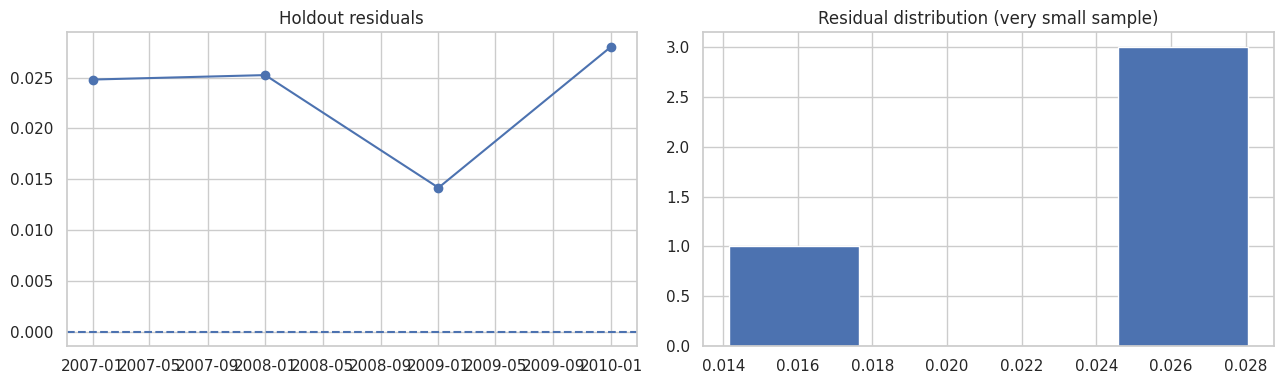

In [ ]:
if results:
    best_name = pd.DataFrame(results).sort_values("RMSE").iloc[0]["Model"]
    residuals = test - predictions[best_name]
    print("Lowest holdout RMSE model:", best_name)
    print("Test residual mean:", float(residuals.mean()))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(residuals.index, residuals.values, marker="o")
    axes[0].axhline(0, linestyle="--")
    axes[0].set_title("Holdout residuals")
    axes[1].hist(residuals.values, bins=max(3, len(residuals)))
    axes[1].set_title("Residual distribution (very small sample)")
    plt.tight_layout()
    plt.show()

## 10. Interpretation and conclusion (write-up guide)

Use your actual comparison table and plots to complete these points:

- **Trend:** Describe whether the state-average prevalence of everyday smoking rises, falls, or changes direction over 1995–2010. Cite the plotted values rather than assuming a trend.
- **Variation / subgroup differences:** Use the state plots and heatmap to identify states that appear consistently higher or lower, while noting that this is an unweighted state-level comparison.
- **Forecasting:** Report the lowest MAE/RMSE model on the chronological holdout, alongside the scores of all alternatives. Lower values indicate smaller forecast errors in percentage-point units (MAPE is in percent).
- **Model assumptions:** AR uses lagged target values; MA uses lagged forecast errors; ARMA assumes a stationary series; ARIMA uses differencing for non-stationarity; Holt-Winters captures level/trend; ARIMAX/SARIMAX depend on exogenous predictors being available; VAR models interactions across multiple series.
- **Seasonality:** Because observations are annual, there is no intra-year seasonal cycle to estimate. The SARIMA seasonal period used above is an exploratory technical comparison only, not evidence of real annual-data seasonality.
- **Domain meaning:** A forecast is an estimate of future prevalence, not a causal claim or an estimate of an individual's health risk. Public-health interpretation should account for survey design, weighting, confidence intervals, changes in survey methodology, and the limited time span.
- **Limitations:** Short series, simple state average, potential missing-value imputation, no population weighting, and a small test set. A stronger study would use longer CDC data, survey weights/uncertainty estimates, and rolling-origin validation.

## 11. Export the cleaned annual data and forecasts

In [ ]:
annual.to_csv("cleaned_annual_smoking_series.csv")
if results:
    forecast_export = pd.DataFrame({"Actual": test})
    for name, forecast in predictions.items():
        forecast_export[name] = forecast
    forecast_export.to_csv("test_period_forecasts.csv")
    print("Created: cleaned_annual_smoking_series.csv, test_period_forecasts.csv")

Created: cleaned_annual_smoking_series.csv, test_period_forecasts.csv


# Milestone3

Implement advanced models (as applicable):

	1. RNN models like LSTM and GRU
	2  XGBoost
	3  Prophet
	4. ARCH/GARCH/VAR
	5. Any one Time series Transformers (informer, autoformer, TFT, PatchTST etc.)
• Fine-tune models and improve performance
• Perform comparative analysis
• Derive actionable insights
• Evaluate models using error metrics such as RMSE, MAE, and MAPE.
• Compare all these forecasting approaches in table and plots.
• Interpret forecasting results in context of the real-world domain.

Install XGBoost

In [ ]:
!pip install -q xgboost

Import libraries and check data

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Dataset shape:", df.shape)
print("Years:", df["Year"].min(), "-", df["Year"].max())
print("Number of states:", df["State"].nunique())

display(df[["Year", "State", "Smoke everyday"]].head())

Dataset shape: (876, 9)
Years: 1995 - 2010
Number of states: 56


,Year,State,Smoke everyday
825,1995,Alabama,21.9
772,1996,Alabama,17.6
718,1997,Alabama,20.8
664,1998,Alabama,19.4
610,1999,Alabama,18.1


Feature engineering

In [ ]:
# Prepare the data
xgb_data = df[[
    "Year",
    "State",
    "Smoke everyday"
]].copy()

xgb_data = xgb_data.sort_values(
    ["State", "Year"]
).reset_index(drop=True)

# Create exact calendar-year lag features
# This avoids treating a two-year gap as a one-year lag.

for lag in [1, 2, 3]:

    lag_data = xgb_data[
        ["Year", "State", "Smoke everyday"]
    ].copy()

    lag_data["Year"] += lag

    lag_data = lag_data.rename(
        columns={
            "Smoke everyday": f"lag_{lag}"
        }
    )

    xgb_data = xgb_data.merge(
        lag_data,
        on=["Year", "State"],
        how="left"
    )

# Rolling average of previous three years
xgb_data["rolling_mean_3"] = (
    xgb_data[["lag_1", "lag_2", "lag_3"]].mean(axis=1)
)

# Keep observations with complete lag history
xgb_data = xgb_data.dropna(
    subset=["lag_1", "lag_2", "lag_3"]
).reset_index(drop=True)

print("Feature dataset shape:", xgb_data.shape)

display(xgb_data.head(10))

Feature dataset shape: (702, 7)


,Year,State,Smoke everyday,lag_1,lag_2,lag_3,rolling_mean_3
0,1998,Alabama,19.4,20.8,17.6,21.9,20.100000
1,1999,Alabama,18.1,19.4,20.8,17.6,19.266667
2,2000,Alabama,19.3,18.1,19.4,20.8,19.433333
3,2001,Alabama,17.4,19.3,18.1,19.4,18.933333
4,2002,Alabama,19.2,17.4,19.3,18.1,18.266667
5,2003,Alabama,19.7,19.2,17.4,19.3,18.633333
6,2004,Alabama,18.7,19.7,19.2,17.4,18.766667
7,2005,Alabama,18.8,18.7,19.7,19.2,19.200000
8,2006,Alabama,17.6,18.8,18.7,19.7,19.066667
9,2007,Alabama,16.5,17.6,18.8,18.7,18.366667


Chronological training and testing split

In [ ]:
# Training data: up to 2006
# Testing data: 2007 onwards

train_xgb = xgb_data[
    xgb_data["Year"] <= 2006
].copy()

test_xgb = xgb_data[
    xgb_data["Year"] >= 2007
].copy()

print("Training period:",
      train_xgb["Year"].min(),
      "-",
      train_xgb["Year"].max())

print("Testing period:",
      test_xgb["Year"].min(),
      "-",
      test_xgb["Year"].max())

print("Training observations:", len(train_xgb))
print("Testing observations:", len(test_xgb))

Training period: 1998 - 2006
Testing period: 2007 - 2010
Training observations: 482
Testing observations: 220


Prepare model input

In [ ]:
numeric_features = [
    "Year",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3"
]

# State encoding
all_states = sorted(df["State"].unique())

def prepare_xgb_features(data):

    numerical = data[numeric_features].reset_index(drop=True)

    categorical = pd.get_dummies(
        data["State"],
        prefix="State",
        dtype=int
    ).reset_index(drop=True)

    categorical = categorical.reindex(
        columns=[f"State_{s}" for s in all_states],
        fill_value=0
    )

    return pd.concat(
        [numerical, categorical],
        axis=1
    )

X_train = prepare_xgb_features(train_xgb)

y_train = train_xgb["Smoke everyday"].reset_index(drop=True)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (482, 61)
y_train shape: (482,)


Train XGBoost model

In [ ]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed successfully!")

XGBoost training completed successfully!


Recursive forecasting (2007–2010)

In [ ]:

# ==========================================
# XGBOOST RECURSIVE FORECASTING: 2007–2010
# ==========================================

# Store historical observations up to 2006
history = {}

for _, row in df[df["Year"] <= 2006].iterrows():
    history[(row["State"], int(row["Year"]))] = float(
        row["Smoke everyday"]
    )

forecast_results = []

forecast_years = [2007, 2008, 2009, 2010]

for year in forecast_years:

    future_rows = []

    states_this_year = sorted(
        df.loc[df["Year"] == year, "State"].unique()
    )

    for state in states_this_year:

        lag1 = history.get((state, year - 1))
        lag2 = history.get((state, year - 2))
        lag3 = history.get((state, year - 3))

        if any(v is None for v in [lag1, lag2, lag3]):
            continue

        future_rows.append({
            "Year": year,
            "State": state,
            "lag_1": lag1,
            "lag_2": lag2,
            "lag_3": lag3,
            "rolling_mean_3": np.mean([lag1, lag2, lag3])
        })

    future_df = pd.DataFrame(future_rows)

    if future_df.empty:
        raise ValueError(f"No predictions available for {year}")

    # Prepare features
    X_future = prepare_xgb_features(future_df)

    # Predict
    future_df["Predicted"] = xgb_model.predict(X_future)

    forecast_results.append(future_df.copy())

    # Update history using predictions only
    for _, row in future_df.iterrows():
        history[(row["State"], year)] = row["Predicted"]

# Combine yearly results
xgb_recursive_results = pd.concat(
    forecast_results,
    ignore_index=True
)

# Annual average prediction
xgb_annual = (
    xgb_recursive_results
    .groupby("Year")["Predicted"]
    .mean()
)

# Convert year index to the same datetime convention as y
xgb_forecast = xgb_annual.copy()
xgb_forecast.index = pd.to_datetime(
    xgb_forecast.index.astype(str),
    format="%Y"
)

print("Recursive forecasting completed!")

display(xgb_recursive_results.head(10))
display(xgb_forecast.to_frame("XGBoost Forecast"))


Recursive forecasting completed!


,Year,State,lag_1,lag_2,lag_3,rolling_mean_3,Predicted
0,2007,Alabama,17.6,18.8,18.7,18.366667,17.042400
1,2007,Alaska,16.2,18.8,16.4,17.133333,15.538651
2,2007,Arizona,12.1,13.7,13.5,13.100000,11.473391
3,2007,Arkansas,18.8,18.1,19.4,18.766667,17.597080
4,2007,California,9.4,9.8,10.0,9.733333,8.274871
5,2007,Colorado,12.3,13.5,13.8,13.200000,11.960378
6,2007,Connecticut,11.9,12.4,13.2,12.500000,10.555512
7,2007,Delaware,16.7,15.5,18.8,17.000000,15.613999
8,2007,District of Columbia,10.6,11.6,12.5,11.566667,9.792223
9,2007,Florida,16.0,15.2,14.6,15.266667,14.599680


,XGBoost Forecast
Year,
2007-01-01,14.070410
2008-01-01,13.494422
2009-01-01,12.874513
2010-01-01,12.245599


Evaluation metrics

In [ ]:

# ==========================================
# XGBOOST MODEL EVALUATION
# ==========================================

# Match the existing notebook's test dates
xgb_forecast = xgb_forecast.reindex(test.index)

# Check for missing predictions
if xgb_forecast.isna().any():
    raise ValueError(
        "Some test years have missing predictions. "
        "Check the recursive forecasting cell."
    )

# Calculate metrics
xgb_metrics = metrics(
    test.values,
    xgb_forecast.values
)

print("\nXGBOOST PERFORMANCE")
print("=" * 40)

for name, value in xgb_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nActual values:")
display(test)

print("\nPredicted values:")
display(xgb_forecast)



XGBOOST PERFORMANCE
MAE: 0.4582
RMSE: 0.4942
MAPE (%): 3.3494

Actual values:


,Smoke everyday
Date,
2007-01-01,14.742857
2008-01-01,13.771429
2009-01-01,13.146429
2010-01-01,12.857143



Predicted values:


,Predicted
Date,
2007-01-01,14.070410
2008-01-01,13.494422
2009-01-01,12.874513
2010-01-01,12.245599


Add to comparison table

In [ ]:

# ==========================================
# ADD XGBOOST TO EXISTING MODEL COMPARISON
# ==========================================

model_name = "XGBoost (recursive)"

# Remove previous entry if cell is executed again
results[:] = [
    r for r in results
    if r["Model"] != model_name
]

predictions.pop(model_name, None)

# Add to existing comparison framework
record_model(model_name, xgb_forecast)

comparison = pd.DataFrame(results).sort_values(
    "RMSE"
).reset_index(drop=True)

print("Updated model comparison:")
display(
    comparison.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAPE (%)": "{:.4f}"
    })
)


Updated model comparison:


,Model,MAE,RMSE,MAPE (%)
0,"ARIMAX(1,1,1)",0.0231,0.0237,0.1694
1,"SARIMAX(1,1,1)x(1,0,0,2)",0.0439,0.0459,0.3265
2,Prophet (trend only),0.1877,0.2127,1.3564
3,Holt-Winters (additive trend),0.1878,0.2432,1.3362
4,"SARIMA(1,1,1)x(1,0,0,2)",0.1890,0.2497,1.3431
5,"ARIMA(1,1,1)",0.2108,0.2534,1.5115
6,Differenced VAR(1) (VARIMA-style),0.3589,0.4094,2.5912
7,XGBoost (recursive),0.4582,0.4942,3.3494
8,AR(1),1.4452,1.6724,10.9527
9,"ARMA(1,1)",1.4578,1.7333,11.0816


Forecast visualization

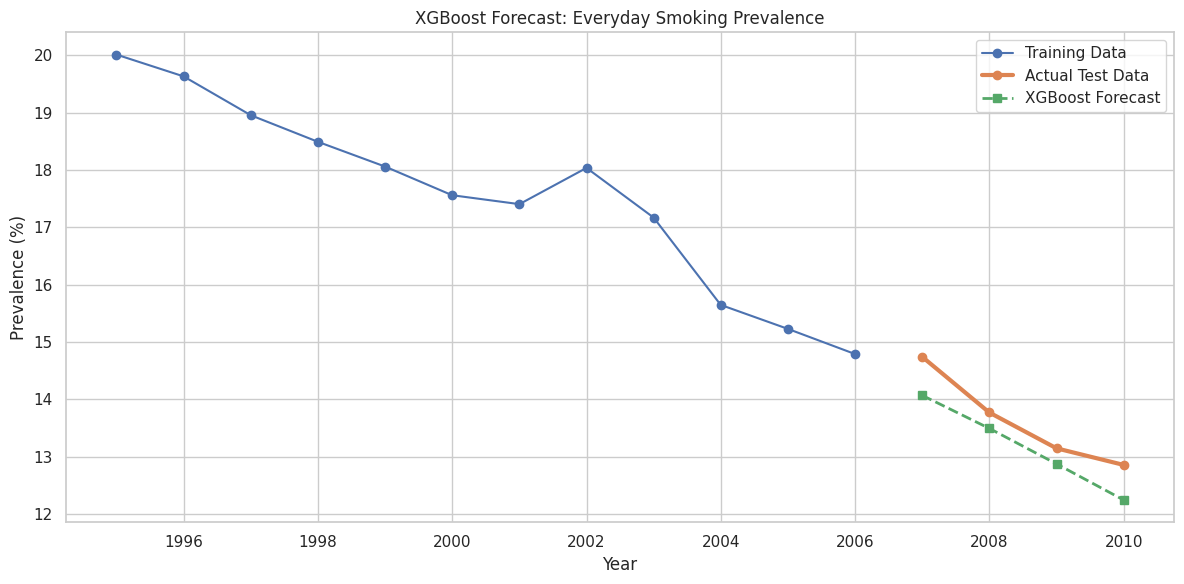

In [ ]:

# ==========================================
# ACTUAL VS XGBOOST PREDICTIONS
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train.values,
    marker="o",
    label="Training Data"
)

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual Test Data"
)

plt.plot(
    xgb_forecast.index,
    xgb_forecast.values,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="XGBoost Forecast"
)

plt.title("XGBoost Forecast: Everyday Smoking Prevalence")
plt.xlabel("Year")
plt.ylabel("Prevalence (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Feature importance

Top 15 important features:


,Feature,Importance
4,rolling_mean_3,0.529500
1,lag_1,0.247474
3,lag_3,0.067158
2,lag_2,0.046128
0,Year,0.030733
23,State_Kentucky,0.027667
7,State_Arizona,0.006767
20,State_Indiana,0.005819
36,State_Nevada,0.005071
12,State_Delaware,0.004497


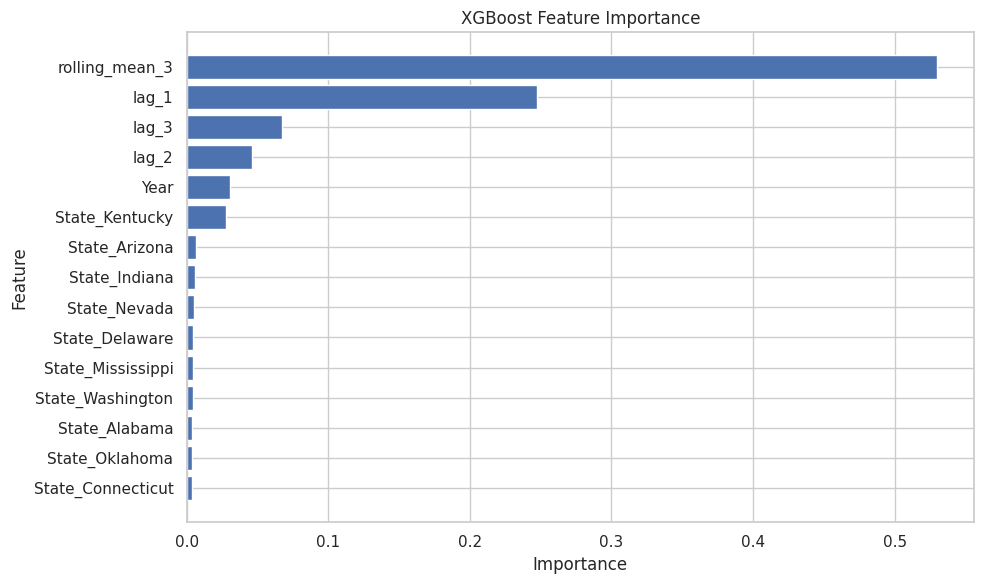

In [ ]:

# ==========================================
# XGBOOST FEATURE IMPORTANCE
# ==========================================

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 important features:")
display(importance.head(15))

plt.figure(figsize=(10, 6))

top_features = importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# VERIFY ORIGINAL XGBOOST RESULTS
# ==========================================

# Match predictions with actual state-level observations
xgb_check = xgb_recursive_results.merge(
    df[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

# Calculate actual and predicted averages
xgb_check_annual = xgb_check.groupby("Year").agg(
    Actual=("Smoke everyday", "mean"),
    Predicted=("Predicted", "mean"),
    States=("State", "nunique")
)

print("XGBoost state-level coverage:")
display(xgb_check_annual.round(4))

# Matched-state metrics
matched_metrics = metrics(
    xgb_check_annual["Actual"],
    xgb_check_annual["Predicted"]
)

print("\nMatched-state evaluation:")
for name, value in matched_metrics.items():
    print(f"{name}: {value:.4f}")

# Original notebook comparison uses all available states
full_metrics = metrics(
    test.values,
    xgb_forecast.reindex(test.index).values
)

print("\nFull national-series comparison:")
for name, value in full_metrics.items():
    print(f"{name}: {value:.4f}")


XGBoost state-level coverage:


,Actual,Predicted,States
Year,,,
2007,14.6185,14.0704,54
2008,13.6704,13.4944,54
2009,13.0907,12.8745,54
2010,12.7704,12.2456,54



Matched-state evaluation:
MAE: 0.3663
RMSE: 0.4042
MAPE (%): 2.6994

Full national-series comparison:
MAE: 0.4582
RMSE: 0.4942
MAPE (%): 3.3494


Save baseline and define recursive forecasting function

In [ ]:

# ==========================================
# HYPERPARAMETER TUNING PREPARATION
# ==========================================

from itertools import product

# Preserve the original model forecast
xgb_baseline_forecast = xgb_forecast.copy()

# Function for recursive forecasting
def recursive_xgb_predict(model, cutoff_year, future_years):

    history = {}

    # Only use historical data up to cutoff year
    historical_data = df[df["Year"] <= cutoff_year]

    for _, row in historical_data.iterrows():

        history[(row["State"], int(row["Year"]))] = float(
            row["Smoke everyday"]
        )

    all_predictions = []

    for year in future_years:

        states = sorted(
            df.loc[df["Year"] == year, "State"].unique()
        )

        future_rows = []

        for state in states:

            lag1 = history.get((state, year - 1))
            lag2 = history.get((state, year - 2))
            lag3 = history.get((state, year - 3))

            if any(v is None for v in [lag1, lag2, lag3]):
                continue

            future_rows.append({
                "Year": year,
                "State": state,
                "lag_1": lag1,
                "lag_2": lag2,
                "lag_3": lag3,
                "rolling_mean_3": np.mean([lag1, lag2, lag3])
            })

        future_df = pd.DataFrame(future_rows)

        if future_df.empty:
            continue

        X_future = prepare_xgb_features(future_df)

        future_df["Predicted"] = model.predict(X_future)

        all_predictions.append(future_df.copy())

        # Update history using predictions only
        for _, row in future_df.iterrows():

            history[(row["State"], year)] = row["Predicted"]

    return pd.concat(all_predictions, ignore_index=True)


print("Recursive forecasting function created successfully!")


Recursive forecasting function created successfully!


Define hyperparameter combinations

In [ ]:
# ==========================================
# DEFINE HYPERPARAMETER GRID
# ==========================================

parameter_grid = list(product(
    [100, 200, 300],  # n_estimators
    [1, 2],           # max_depth
    [0.03, 0.05]      # learning_rate
))

print("Total combinations:", len(parameter_grid))

for params in parameter_grid:
    print(params)

Total combinations: 12
(100, 1, 0.03)
(100, 1, 0.05)
(100, 2, 0.03)
(100, 2, 0.05)
(200, 1, 0.03)
(200, 1, 0.05)
(200, 2, 0.03)
(200, 2, 0.05)
(300, 1, 0.03)
(300, 1, 0.05)
(300, 2, 0.03)
(300, 2, 0.05)


Run hyperparameter tuning

In [ ]:
# ==========================================
# XGBOOST HYPERPARAMETER TUNING
# ==========================================

tuning_results = []

validation_cutoffs = [2000, 2001, 2002]

for n_est, depth, lr in parameter_grid:

    params = {
        "n_estimators": n_est,
        "max_depth": depth,
        "learning_rate": lr,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 5,
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": 42,
        "n_jobs": -1
    }

    fold_metrics = []

    for cutoff in validation_cutoffs:

        # Training data only up to cutoff
        fold_train = xgb_data[
            xgb_data["Year"] <= cutoff
        ]

        X_fold = prepare_xgb_features(fold_train)

        y_fold = fold_train["Smoke everyday"]

        # Train model
        fold_model = XGBRegressor(**params)

        fold_model.fit(X_fold, y_fold)

        # Four-year recursive validation
        validation_years = list(
            range(cutoff + 1, cutoff + 5)
        )

        fold_predictions = recursive_xgb_predict(
            fold_model,
            cutoff,
            validation_years
        )

        # Match actual values for forecastable states
        fold_actual = fold_predictions.merge(
            df[["Year", "State", "Smoke everyday"]],
            on=["Year", "State"],
            how="inner"
        )

        annual_fold = fold_actual.groupby("Year").agg(
            Actual=("Smoke everyday", "mean"),
            Predicted=("Predicted", "mean")
        )

        fold_score = metrics(
            annual_fold["Actual"],
            annual_fold["Predicted"]
        )

        fold_metrics.append(fold_score)

    # Average scores across folds
    tuning_results.append({
        **params,
        "MAE": np.mean([m["MAE"] for m in fold_metrics]),
        "RMSE": np.mean([m["RMSE"] for m in fold_metrics]),
        "MAPE (%)": np.mean([m["MAPE (%)"] for m in fold_metrics])
    })

# Create tuning table
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "RMSE"
).reset_index(drop=True)

print("HYPERPARAMETER TUNING COMPLETED")

display(
    tuning_df[
        ["n_estimators", "max_depth", "learning_rate",
         "MAE", "RMSE", "MAPE (%)"]
    ].round(4)
)

HYPERPARAMETER TUNING COMPLETED


,n_estimators,max_depth,learning_rate,MAE,RMSE,MAPE (%)
0,100,1,0.05,0.8909,0.9932,5.5169
1,100,1,0.03,0.9302,1.0470,5.8139
2,200,1,0.03,0.9876,1.0968,6.1233
3,100,2,0.03,1.0104,1.1157,6.2846
4,300,1,0.03,1.0779,1.1895,6.6779
5,200,1,0.05,1.1238,1.2385,6.9720
6,100,2,0.05,1.1471,1.2659,7.1207
7,200,2,0.03,1.1900,1.3022,7.3976
8,300,1,0.05,1.1980,1.3114,7.4434
9,300,2,0.03,1.2557,1.3732,7.8094


Identify the best parameters

In [ ]:
# ==========================================
# SELECT BEST HYPERPARAMETERS
# ==========================================

best_row = tuning_df.iloc[0]

best_params = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": int(best_row["max_depth"]),
    "learning_rate": float(best_row["learning_rate"]),
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 5,
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "random_state": 42,
    "n_jobs": -1
}

print("BEST XGBOOST PARAMETERS")
print("=" * 40)

for key, value in best_params.items():
    print(f"{key}: {value}")

BEST XGBOOST PARAMETERS
n_estimators: 100
max_depth: 1
learning_rate: 0.05
min_child_weight: 5
subsample: 0.8
colsample_bytree: 0.8
reg_alpha: 0.1
reg_lambda: 5
objective: reg:squarederror
eval_metric: rmse
random_state: 42
n_jobs: -1


Fit tuned model and generate forecasts

In [ ]:
# ==========================================
# TRAIN FINAL TUNED XGBOOST MODEL
# ==========================================

train_xgb = xgb_data[
    xgb_data["Year"] <= 2006
].copy()

X_train = prepare_xgb_features(train_xgb)

y_train = train_xgb["Smoke everyday"]

# Train using best parameters
xgb_model = XGBRegressor(**best_params)

xgb_model.fit(X_train, y_train)

print("Tuned XGBoost model trained successfully!")

# Recursive forecast: 2007–2010
xgb_recursive_results = recursive_xgb_predict(
    xgb_model,
    cutoff_year=2006,
    future_years=[2007, 2008, 2009, 2010]
)

# Aggregate state predictions
xgb_annual = (
    xgb_recursive_results
    .groupby("Year")["Predicted"]
    .mean()
)

xgb_forecast = xgb_annual.copy()

xgb_forecast.index = pd.to_datetime(
    xgb_forecast.index.astype(str),
    format="%Y"
)

print("\nTuned XGBoost forecasts:")
display(xgb_forecast.to_frame("Predicted"))

Tuned XGBoost model trained successfully!

Tuned XGBoost forecasts:


,Predicted
Year,
2007-01-01,14.605098
2008-01-01,14.325865
2009-01-01,14.003527
2010-01-01,13.792236


Final evaluation

In [ ]:
# ==========================================
# COMPARE BASELINE VS TUNED XGBOOST
# ==========================================

# Matched-state actual values
tuned_check = xgb_recursive_results.merge(
    df[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

tuned_annual = tuned_check.groupby("Year").agg(
    Actual=("Smoke everyday", "mean"),
    Predicted=("Predicted", "mean")
)

# Matched-state metrics
tuned_matched_metrics = metrics(
    tuned_annual["Actual"],
    tuned_annual["Predicted"]
)

# Full national-series metrics
tuned_full_metrics = metrics(
    test.values,
    xgb_forecast.reindex(test.index).values
)

# Baseline matched-state metrics
baseline_matched = metrics(
    xgb_check_annual["Actual"],
    xgb_check_annual["Predicted"]
)

comparison_xgb = pd.DataFrame([
    {
        "Model": "XGBoost Baseline",
        **baseline_matched
    },
    {
        "Model": "XGBoost Tuned",
        **tuned_matched_metrics
    }
])

print("BASELINE VS TUNED XGBOOST")
display(comparison_xgb.round(4))

print("\nTuned model — full national-series evaluation:")
for name, value in tuned_full_metrics.items():
    print(f"{name}: {value:.4f}")

BASELINE VS TUNED XGBOOST


,Model,MAE,RMSE,MAPE (%)
0,XGBoost Baseline,0.3663,0.4042,2.6994
1,XGBoost Tuned,0.6509,0.7595,4.9654



Tuned model — full national-series evaluation:
MAE: 0.6211
RMSE: 0.6956
MAPE (%): 4.6882


Add tuned XGBoost to the main comparison

In [ ]:
# Rename original entry for clarity
for result in results:
    if result["Model"] == "XGBoost (recursive)":
        result["Model"] = "XGBoost Baseline (recursive)"

if "XGBoost (recursive)" in predictions:
    predictions["XGBoost Baseline (recursive)"] = (
        predictions.pop("XGBoost (recursive)")
    )

# Register tuned model
results[:] = [
    r for r in results
    if r["Model"] != "XGBoost Tuned (recursive)"
]

predictions.pop("XGBoost Tuned (recursive)", None)

record_model(
    "XGBoost Tuned (recursive)",
    xgb_forecast.values
)

# Updated comparison table
comparison = pd.DataFrame(results).sort_values(
    "RMSE"
).reset_index(drop=True)

display(comparison.round(4))

,Model,MAE,RMSE,MAPE (%)
0,"ARIMAX(1,1,1)",0.0231,0.0237,0.1694
1,"SARIMAX(1,1,1)x(1,0,0,2)",0.0439,0.0459,0.3265
2,Prophet (trend only),0.1877,0.2127,1.3564
3,Holt-Winters (additive trend),0.1878,0.2432,1.3362
4,"SARIMA(1,1,1)x(1,0,0,2)",0.1890,0.2497,1.3431
5,"ARIMA(1,1,1)",0.2108,0.2534,1.5115
6,Differenced VAR(1) (VARIMA-style),0.3589,0.4094,2.5912
7,XGBoost Baseline (recursive),0.4582,0.4942,3.3494
8,XGBoost Tuned (recursive),0.6211,0.6956,4.6882
9,AR(1),1.4452,1.6724,10.9527


Compare baseline and tuned forecasts

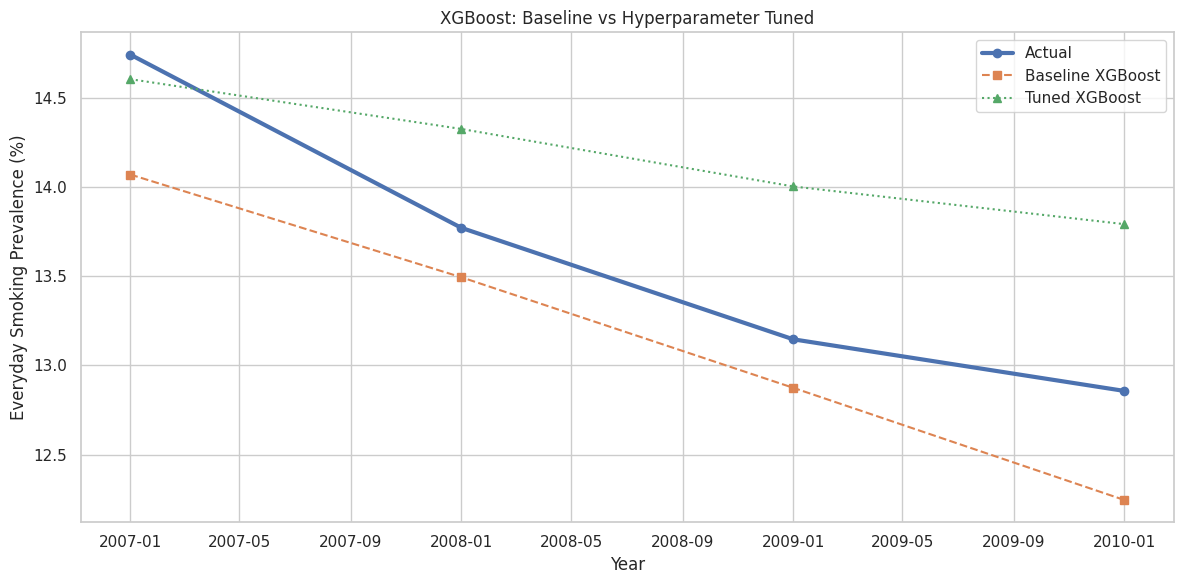

In [ ]:
# ==========================================
# BASELINE VS TUNED FORECAST PLOT
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    xgb_baseline_forecast.index,
    xgb_baseline_forecast.values,
    marker="s",
    linestyle="--",
    label="Baseline XGBoost"
)

plt.plot(
    xgb_forecast.index,
    xgb_forecast.values,
    marker="^",
    linestyle=":",
    label="Tuned XGBoost"
)

plt.title("XGBoost: Baseline vs Hyperparameter Tuned")
plt.xlabel("Year")
plt.ylabel("Everyday Smoking Prevalence (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Plot hyperparameter tuning results

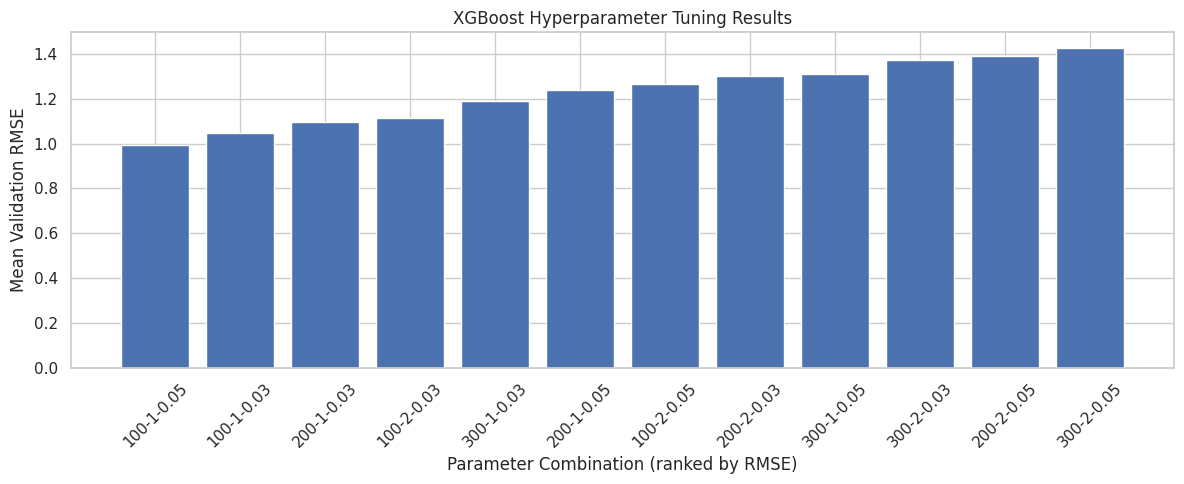

In [ ]:
# ==========================================
# HYPERPARAMETER TUNING VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 5))

plt.bar(
    range(len(tuning_df)),
    tuning_df["RMSE"]
)

plt.title("XGBoost Hyperparameter Tuning Results")
plt.xlabel("Parameter Combination (ranked by RMSE)")
plt.ylabel("Mean Validation RMSE")

plt.xticks(
    range(len(tuning_df)),
    [
        f"{int(r.n_estimators)}-{int(r.max_depth)}-{r.learning_rate}"
        for r in tuning_df.itertuples()
    ],
    rotation=45
)

plt.tight_layout()
plt.show()

#  Implement LSTM

Install and import TensorFlow

In [ ]:
!pip install -q tensorflow

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler

import random

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("TensorFlow version:", tf.__version__)
print("LSTM environment ready!")

TensorFlow version: 2.21.0
LSTM environment ready!


Prepare state-level time-series data

In [ ]:
# ==========================================
# LSTM DATA PREPARATION
# ==========================================

lstm_data = df_raw.copy()

lstm_data.columns = lstm_data.columns.str.strip()

lstm_data["Year"] = pd.to_numeric(
    lstm_data["Year"], errors="coerce"
)

lstm_data["Smoke everyday"] = pd.to_numeric(
    lstm_data["Smoke everyday"], errors="coerce"
)

lstm_data = lstm_data.dropna(
    subset=["Year", "State", "Smoke everyday"]
)

lstm_data["Year"] = lstm_data["Year"].astype(int)

lstm_data = lstm_data.sort_values(
    ["State", "Year"]
).reset_index(drop=True)

print("LSTM dataset shape:", lstm_data.shape)
print("States:", lstm_data["State"].nunique())
print("Years:", lstm_data["Year"].min(), "-", lstm_data["Year"].max())

display(lstm_data.head())

LSTM dataset shape: (876, 9)
States: 56
Years: 1995 - 2010


,Year,State,Smoke everyday,Smoke some days,Former smoker,Never smoked,Location 1,Counties,States
0,1995,Alabama,21.9,2.1,21.1,54.8,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0
1,1996,Alabama,17.6,4.8,21.5,56.1,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0
2,1997,Alabama,20.8,3.9,22.0,53.3,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0
3,1998,Alabama,19.4,5.2,21.5,53.9,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0
4,1999,Alabama,18.1,5.3,24.2,52.3,"{'latitude': '32.840569999605975', 'longitude'...",94.0,29.0


Create sequential training samples

In [ ]:
# ==========================================
# CREATE LSTM SEQUENCES
# ==========================================

SEQUENCE_LENGTH = 3

def create_lstm_sequences(data, max_target_year=None):

    X = []
    y_values = []
    target_years = []
    state_names = []

    for state, group in data.groupby("State"):

        group = group.sort_values("Year")

        years = group["Year"].to_numpy()
        values = group["Smoke everyday"].to_numpy()

        for i in range(SEQUENCE_LENGTH, len(group)):

            # Ensure years are consecutive
            input_years = years[i-SEQUENCE_LENGTH:i]

            if not np.all(np.diff(input_years) == 1):
                continue

            target_year = years[i]

            if (
                max_target_year is not None
                and target_year > max_target_year
            ):
                continue

            X.append(
                values[i-SEQUENCE_LENGTH:i]
            )

            y_values.append(values[i])
            target_years.append(target_year)
            state_names.append(state)

    return (
        np.array(X, dtype=np.float32).reshape(-1, SEQUENCE_LENGTH, 1),
        np.array(y_values, dtype=np.float32),
        np.array(target_years),
        np.array(state_names)
    )


# All available training sequences up to 2006
X_all, y_all, years_all, states_all = create_lstm_sequences(
    lstm_data,
    max_target_year=2006
)

print("Total training sequences:", len(X_all))
print("Input shape:", X_all.shape)
print("Target shape:", y_all.shape)

print("Available target years:", np.unique(years_all))

Total training sequences: 483
Input shape: (483, 3, 1)
Target shape: (483,)
Available target years: [1998 1999 2000 2001 2002 2003 2004 2005 2006]


Create training and validation sets

In [ ]:
# ==========================================
# CHRONOLOGICAL TRAIN / VALIDATION SPLIT
# ==========================================

train_mask = years_all <= 2003

val_mask = (
    (years_all >= 2004) &
    (years_all <= 2006)
)

X_train_lstm = X_all[train_mask]
y_train_lstm = y_all[train_mask]

X_val_lstm = X_all[val_mask]
y_val_lstm = y_all[val_mask]

print("Training sequences:", len(X_train_lstm))
print("Validation sequences:", len(X_val_lstm))

print("Training years:",
      years_all[train_mask].min(),
      "-",
      years_all[train_mask].max())

print("Validation years:",
      years_all[val_mask].min(),
      "-",
      years_all[val_mask].max())

Training sequences: 320
Validation sequences: 163
Training years: 1998 - 2003
Validation years: 2004 - 2006


Normalize the data

In [ ]:
# ==========================================
# DATA NORMALIZATION
# ==========================================

lstm_scaler = MinMaxScaler()

# Fit scaler only on training observations
scaler_values = np.concatenate([
    X_train_lstm.reshape(-1, 1),
    y_train_lstm.reshape(-1, 1)
])

lstm_scaler.fit(scaler_values)

# Transform inputs
X_train_scaled = lstm_scaler.transform(
    X_train_lstm.reshape(-1, 1)
).reshape(-1, SEQUENCE_LENGTH, 1)

X_val_scaled = lstm_scaler.transform(
    X_val_lstm.reshape(-1, 1)
).reshape(-1, SEQUENCE_LENGTH, 1)

# Transform targets
y_train_scaled = lstm_scaler.transform(
    y_train_lstm.reshape(-1, 1)
).ravel()

y_val_scaled = lstm_scaler.transform(
    y_val_lstm.reshape(-1, 1)
).ravel()

print("Normalization completed!")

Normalization completed!


Build the LSTM architecture

In [ ]:
# ==========================================
# BUILD LSTM MODEL
# ==========================================

def build_lstm_model():

    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, 1)),

        LSTM(
            units=16,
            activation="tanh"
        ),

        Dropout(0.1),

        Dense(8, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


lstm_model = build_lstm_model()

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297 (5.07 KB)

 Trainable params: 1,297 (5.07 KB)

 Non-trainable params: 0 (0.00 B)

Train the LSTM model

In [ ]:
# ==========================================
# TRAIN LSTM MODEL
# ==========================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train_scaled,
    y_train_scaled,

    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),

    epochs=200,
    batch_size=16,

    callbacks=[early_stop],

    shuffle=False,
    verbose=1
)

print("LSTM training completed!")
print("Epochs executed:", len(lstm_history.history["loss"]))

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - loss: 0.1050 - mae: 0.2991 - val_loss: 0.0186 - val_mae: 0.1107
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0204 - mae: 0.1097 - val_loss: 0.0166 - val_mae: 0.1098
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0097 - mae: 0.0804 - val_loss: 0.0173 - val_mae: 0.1131
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0101 - mae: 0.0765 - val_loss: 0.0131 - val_mae: 0.0959
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0079 - mae: 0.0678 - val_loss: 0.0131 - val_mae: 0.0974
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0091 - mae: 0.0726 - val_loss: 0.0122 - val_mae: 0.0938
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0077 - mae: 0.0690 - val_loss: 0.0111 - val_mae: 0.0895
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0073 - mae: 0.0658 - val_loss: 0.0101 - val_mae: 0.0851
Epoch 9/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - lo

Visualize training performance

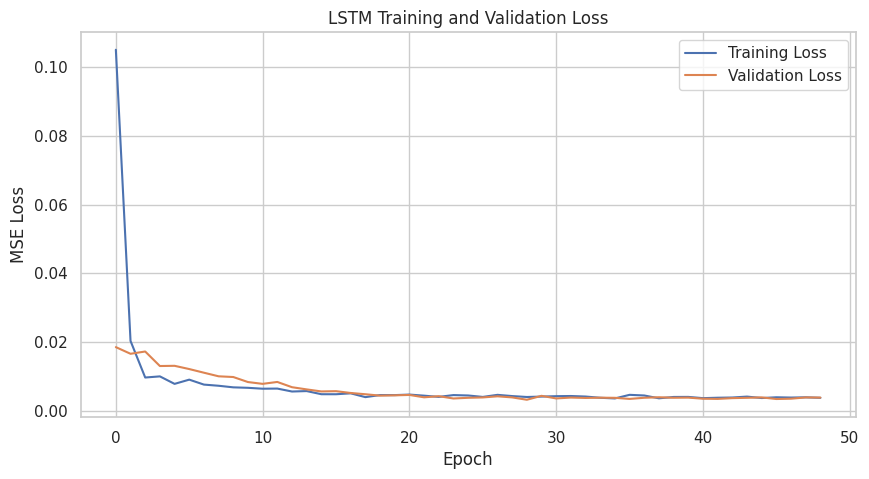

In [ ]:
# ==========================================
# LSTM TRAINING HISTORY
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

# Generate final LSTM forecasts (2007–2010)

Train final LSTM

In [ ]:
# ==========================================
# FINAL LSTM TRAINING UP TO 2006
# ==========================================

best_epoch = np.argmin(
    lstm_history.history["val_loss"]
) + 1

print("Best epoch selected:", best_epoch)

# Fit a new scaler on all training sequences
final_lstm_scaler = MinMaxScaler()

final_scaler_values = np.concatenate([
    X_all.reshape(-1, 1),
    y_all.reshape(-1, 1)
])

final_lstm_scaler.fit(final_scaler_values)

X_final_scaled = final_lstm_scaler.transform(
    X_all.reshape(-1, 1)
).reshape(-1, SEQUENCE_LENGTH, 1)

y_final_scaled = final_lstm_scaler.transform(
    y_all.reshape(-1, 1)
).ravel()

# Build a fresh model
final_lstm_model = build_lstm_model()

# Train on all data available through 2006
final_lstm_history = final_lstm_model.fit(
    X_final_scaled,
    y_final_scaled,
    epochs=best_epoch,
    batch_size=16,
    shuffle=False,
    verbose=1
)

print("Final LSTM model trained!")

Best epoch selected: 29
Epoch 1/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.2767 - mae: 0.5009
Epoch 2/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1780 - mae: 0.3971
Epoch 3/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0916 - mae: 0.2748
Epoch 4/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0330 - mae: 0.1466
Epoch 5/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0145 - mae: 0.0917
Epoch 6/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0135 - mae: 0.0877
Epoch 7/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0130 - mae: 0.0875
Epoch 8/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0127 - mae: 0.0854
Epoch 9/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0117 - mae: 0.0854
Epoch 10/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0111 - mae: 0.0809
Epoch 11/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0107 - mae: 0.0791
Epoch 12/29
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0107 - mae: 0.0805
Epoch 13/29
31/31 ━━━━━━━

Recursive forecasting

In [ ]:
# ==========================================
# LSTM RECURSIVE FORECASTING
# ==========================================

lstm_history_values = {}

# Historical observations available up to 2006
for _, row in lstm_data[
    lstm_data["Year"] <= 2006
].iterrows():

    lstm_history_values[
        (row["State"], int(row["Year"]))
    ] = float(row["Smoke everyday"])


lstm_forecast_results = []

for year in [2007, 2008, 2009, 2010]:

    future_rows = []

    states_this_year = sorted(
        lstm_data.loc[
            lstm_data["Year"] == year,
            "State"
        ].unique()
    )

    for state in states_this_year:

        values = [
            lstm_history_values.get((state, year - 3)),
            lstm_history_values.get((state, year - 2)),
            lstm_history_values.get((state, year - 1))
        ]

        if any(v is None for v in values):
            continue

        sequence = np.array(
            values,
            dtype=np.float32
        ).reshape(1, SEQUENCE_LENGTH, 1)

        # Scale input
        sequence_scaled = final_lstm_scaler.transform(
            sequence.reshape(-1, 1)
        ).reshape(1, SEQUENCE_LENGTH, 1)

        # Predict scaled output
        prediction_scaled = final_lstm_model.predict(
            sequence_scaled,
            verbose=0
        )

        # Convert prediction back to original scale
        prediction = final_lstm_scaler.inverse_transform(
            prediction_scaled
        )[0, 0]

        future_rows.append({
            "Year": year,
            "State": state,
            "Predicted": float(prediction)
        })

    future_df = pd.DataFrame(future_rows)

    if future_df.empty:
        raise ValueError(
            f"No valid LSTM predictions for {year}"
        )

    lstm_forecast_results.append(future_df)

    # Use predictions for subsequent forecast years
    for _, row in future_df.iterrows():

        lstm_history_values[
            (row["State"], year)
        ] = row["Predicted"]


lstm_forecast_results = pd.concat(
    lstm_forecast_results,
    ignore_index=True
)

# Annual mean forecast
lstm_annual = (
    lstm_forecast_results
    .groupby("Year")["Predicted"]
    .mean()
)

lstm_forecast = lstm_annual.copy()

lstm_forecast.index = pd.to_datetime(
    lstm_forecast.index.astype(str),
    format="%Y"
)

print("LSTM recursive forecasting completed!")

display(lstm_forecast_results.head())
display(lstm_forecast.to_frame("LSTM Forecast"))

LSTM recursive forecasting completed!


,Year,State,Predicted
0,2007,Alabama,17.322943
1,2007,Alaska,16.224331
2,2007,Arizona,13.015594
3,2007,Arkansas,17.627262
4,2007,California,10.601246


,LSTM Forecast
Year,
2007-01-01,14.791605
2008-01-01,14.535072
2009-01-01,14.310878
2010-01-01,14.156073


Calculate evaluation metrics

In [ ]:
# ==========================================
# LSTM EVALUATION
# ==========================================

lstm_evaluation = lstm_forecast_results.merge(
    lstm_data[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

lstm_annual_comparison = lstm_evaluation.groupby(
    "Year"
).agg(
    Actual=("Smoke everyday", "mean"),
    Predicted=("Predicted", "mean"),
    States=("State", "nunique")
)

lstm_metrics = metrics(
    lstm_annual_comparison["Actual"],
    lstm_annual_comparison["Predicted"]
)

print("LSTM MODEL PERFORMANCE")
print("=" * 40)

for name, value in lstm_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nActual vs Predicted:")
display(lstm_annual_comparison.round(4))

LSTM MODEL PERFORMANCE
MAE: 0.9109
RMSE: 1.0231
MAPE (%): 6.9202

Actual vs Predicted:


,Actual,Predicted,States
Year,,,
2007,14.6185,14.7916,54
2008,13.6704,14.5351,54
2009,13.0907,14.3109,54
2010,12.7704,14.1561,54


Actual vs predicted graph

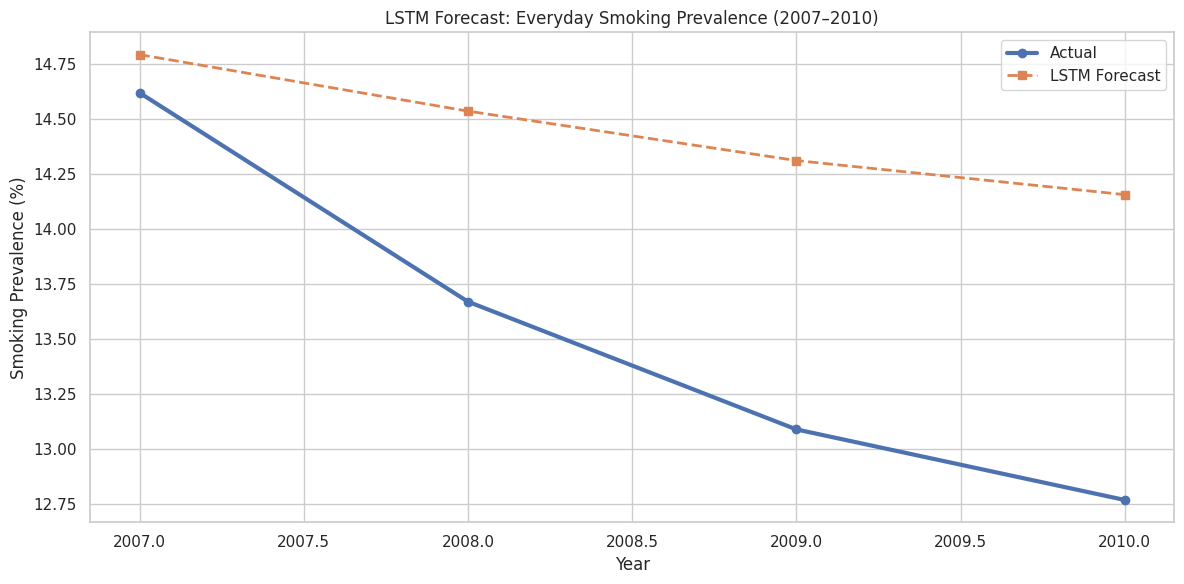

In [ ]:
# ==========================================
# LSTM FORECAST VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    lstm_annual_comparison.index,
    lstm_annual_comparison["Actual"],
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    lstm_annual_comparison.index,
    lstm_annual_comparison["Predicted"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="LSTM Forecast"
)

plt.title(
    "LSTM Forecast: Everyday Smoking Prevalence (2007–2010)"
)

plt.xlabel("Year")
plt.ylabel("Smoking Prevalence (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Compare LSTM with tuned XGBoost

XGBoost vs LSTM

In [ ]:
# ==========================================
# XGBOOST VS LSTM: COMMON STATE COMPARISON
# ==========================================

xgb_compare = xgb_recursive_results[
    ["Year", "State", "Predicted"]
].rename(
    columns={"Predicted": "XGBoost"}
)

lstm_compare = lstm_forecast_results[
    ["Year", "State", "Predicted"]
].rename(
    columns={"Predicted": "LSTM"}
)

# Keep only state-year combinations forecast by both models
common_results = xgb_compare.merge(
    lstm_compare,
    on=["Year", "State"],
    how="inner"
)

common_results = common_results.merge(
    lstm_data[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

common_annual = common_results.groupby("Year").agg(
    Actual=("Smoke everyday", "mean"),
    XGBoost=("XGBoost", "mean"),
    LSTM=("LSTM", "mean")
)

print("COMMON STATE COMPARISON")
display(common_annual.round(4))

# Calculate comparable metrics
common_metrics = pd.DataFrame([
    {
        "Model": "XGBoost Tuned",
        **metrics(common_annual["Actual"], common_annual["XGBoost"])
    },
    {
        "Model": "LSTM",
        **metrics(common_annual["Actual"], common_annual["LSTM"])
    }
])

print("\nMODEL PERFORMANCE COMPARISON")
display(common_metrics.round(4))

COMMON STATE COMPARISON


,Actual,XGBoost,LSTM
Year,,,
2007,14.6185,14.6051,14.7916
2008,13.6704,14.3259,14.5351
2009,13.0907,14.0035,14.3109
2010,12.7704,13.7922,14.1561



MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,MAPE (%)
0,XGBoost Tuned,0.6509,0.7595,4.9654
1,LSTM,0.9109,1.0231,6.9202


Comparison graph

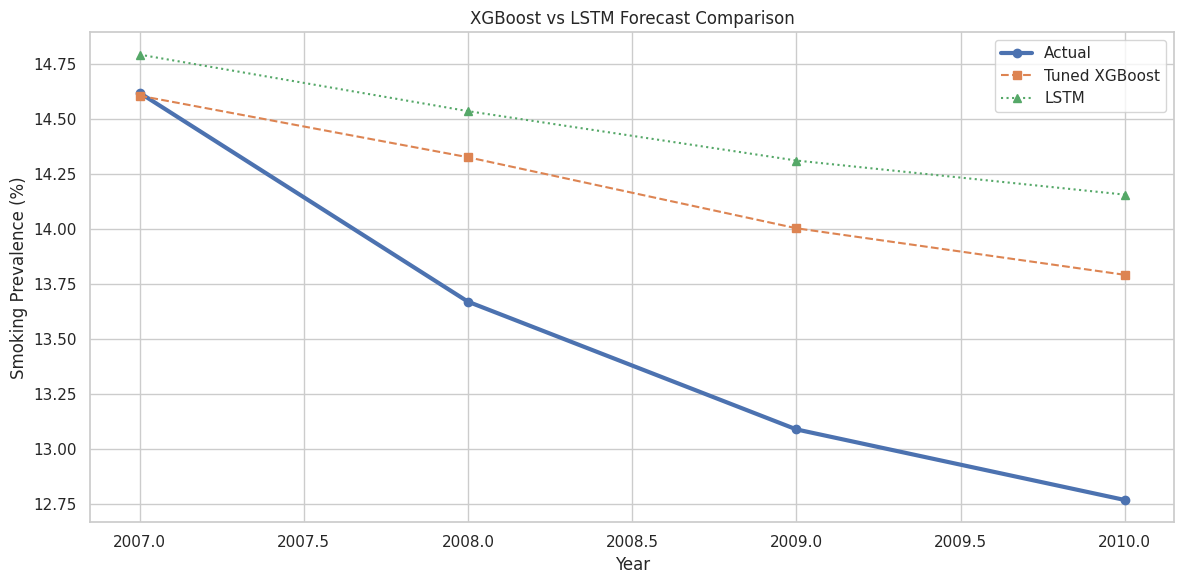

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    common_annual.index,
    common_annual["Actual"],
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    common_annual.index,
    common_annual["XGBoost"],
    marker="s",
    linestyle="--",
    label="Tuned XGBoost"
)

plt.plot(
    common_annual.index,
    common_annual["LSTM"],
    marker="^",
    linestyle=":",
    label="LSTM"
)

plt.title("XGBoost vs LSTM Forecast Comparison")
plt.xlabel("Year")
plt.ylabel("Smoking Prevalence (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# GRU Model

In [ ]:
Build GRU model

In [ ]:
from tensorflow.keras.layers import GRU

def build_gru_model():
    model = Sequential([
        Input(shape=(3, 1)),
        GRU(16, activation="tanh"),
        Dropout(0.1),
        Dense(8, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

gru_model = build_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 16)             │           912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Prepare GRU training and validation data

In [ ]:
# Training: target years up to 2003
gru_train_mask = years_all <= 2003

# Validation: target years 2004 to 2006
gru_val_mask = (years_all >= 2004) & (years_all <= 2006)

X_gru_train = X_all[gru_train_mask]
y_gru_train = y_all[gru_train_mask]

X_gru_val = X_all[gru_val_mask]
y_gru_val = y_all[gru_val_mask]

# Separate scalers for input and target
gru_X_scaler = MinMaxScaler()
gru_y_scaler = MinMaxScaler()

X_gru_train_scaled = gru_X_scaler.fit_transform(
    X_gru_train.reshape(-1, 1)
).reshape(X_gru_train.shape)

X_gru_val_scaled = gru_X_scaler.transform(
    X_gru_val.reshape(-1, 1)
).reshape(X_gru_val.shape)

y_gru_train_scaled = gru_y_scaler.fit_transform(
    y_gru_train.reshape(-1, 1)
)

y_gru_val_scaled = gru_y_scaler.transform(
    y_gru_val.reshape(-1, 1)
)

print("Training sequences:", len(X_gru_train))
print("Validation sequences:", len(X_gru_val))
print("Training shape:", X_gru_train_scaled.shape)

Training sequences: 320
Validation sequences: 163
Training shape: (320, 3, 1)


Train GRU model

In [ ]:
gru_model = build_gru_model()

gru_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_gru_train_scaled,
    y_gru_train_scaled,
    validation_data=(X_gru_val_scaled, y_gru_val_scaled),
    epochs=200,
    batch_size=16,
    callbacks=[gru_early_stop],
    shuffle=False,
    verbose=1
)

best_gru_epoch = np.argmin(gru_history.history["val_loss"]) + 1

print("Best GRU epoch:", best_gru_epoch)

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - loss: 0.2311 - mae: 0.4540 - val_loss: 0.0951 - val_mae: 0.2810
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.1425 - mae: 0.3525 - val_loss: 0.0511 - val_mae: 0.1991
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0789 - mae: 0.2536 - val_loss: 0.0208 - val_mae: 0.1123
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0307 - mae: 0.1398 - val_loss: 0.0143 - val_mae: 0.0930
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0132 - mae: 0.0904 - val_loss: 0.0240 - val_mae: 0.1327
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0131 - mae: 0.0890 - val_loss: 0.0198 - val_mae: 0.1196
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0130 - mae: 0.0857 - val_loss: 0.0165 - val_mae: 0.1088
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0108 - mae: 0.0813 - val_loss: 0.0135 - val_mae: 0.0970
Epoch 9/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - lo

Plot GRU training performance

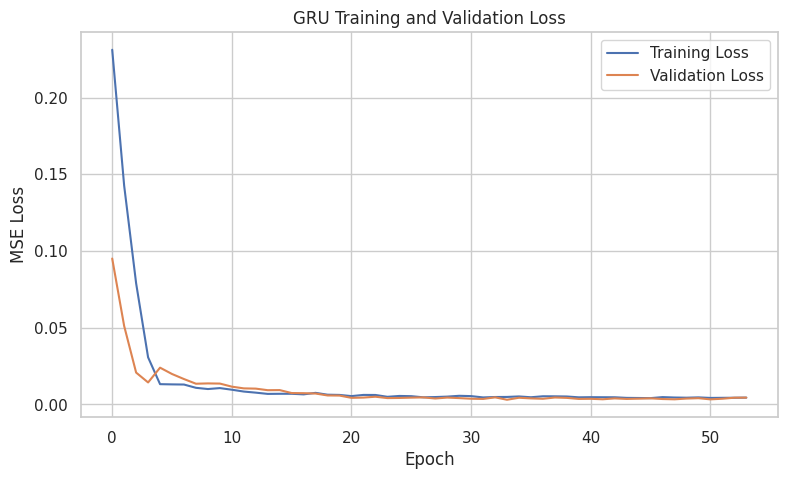

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(gru_history.history["loss"], label="Training Loss")
plt.plot(gru_history.history["val_loss"], label="Validation Loss")

plt.title("GRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

Train final GRU model

In [ ]:
# Fit fresh scalers using all sequences available through 2006
gru_final_X_scaler = MinMaxScaler()
gru_final_y_scaler = MinMaxScaler()

X_gru_all_scaled = gru_final_X_scaler.fit_transform(
    X_all.reshape(-1, 1)
).reshape(X_all.shape)

y_gru_all_scaled = gru_final_y_scaler.fit_transform(
    y_all.reshape(-1, 1)
)

# Build and train final model
final_gru_model = build_gru_model()

final_gru_model.fit(
    X_gru_all_scaled,
    y_gru_all_scaled,
    epochs=best_gru_epoch,
    batch_size=16,
    shuffle=False,
    verbose=1
)

print("Final GRU model trained successfully.")

Epoch 1/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0602 - mae: 0.2030
Epoch 2/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0096 - mae: 0.0800
Epoch 3/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0101 - mae: 0.0772
Epoch 4/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0076 - mae: 0.0701
Epoch 5/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0073 - mae: 0.0654
Epoch 6/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0081 - mae: 0.0699
Epoch 7/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0070 - mae: 0.0662
Epoch 8/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0059 - mae: 0.0604
Epoch 9/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0063 - mae: 0.0607
Epoch 10/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0053 - mae: 0.0564
Epoch 11/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0052 - mae: 0.0578
Epoch 12/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0053 - mae: 0.0562
Epoch 13/34
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/st

Recursive forecasting for 2007–2010

In [ ]:
gru_forecast_results = []

for state in sorted(lstm_data["State"].unique()):

    state_data = (
        lstm_data[lstm_data["State"] == state]
        .sort_values("Year")
    )

    # Use the three consecutive observations ending in 2006
    history = state_data[state_data["Year"] <= 2006].tail(3)

    if len(history) != 3:
        continue

    history_years = history["Year"].tolist()

    if history_years != [2004, 2005, 2006]:
        continue

    values = history["Smoke everyday"].astype(float).tolist()

    for year in range(2007, 2011):

        input_sequence = np.array(values[-3:]).reshape(-1, 1)

        scaled_sequence = gru_final_X_scaler.transform(
            input_sequence
        ).reshape(1, 3, 1)

        scaled_prediction = final_gru_model.predict(
            scaled_sequence,
            verbose=0
        )

        prediction = gru_final_y_scaler.inverse_transform(
            scaled_prediction
        )[0, 0]

        gru_forecast_results.append({
            "Year": year,
            "State": state,
            "Predicted": float(prediction)
        })

        # Add prediction to history for next year's forecast
        values.append(float(prediction))


gru_forecast_results = pd.DataFrame(gru_forecast_results)

print("GRU forecasting completed.")
display(gru_forecast_results.head(10))

GRU forecasting completed.


,Year,State,Predicted
0,2007,Alabama,17.247185
1,2008,Alabama,16.749361
2,2009,Alabama,16.194359
3,2010,Alabama,15.737425
4,2007,Alaska,16.194586
5,2008,Alaska,15.873016
6,2009,Alaska,15.230212
7,2010,Alaska,14.858776
8,2007,Arizona,12.381013
9,2008,Arizona,12.067691


Evaluate GRU predictions

In [ ]:
gru_evaluation = gru_forecast_results.merge(
    lstm_data[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

gru_annual = (
    gru_evaluation.groupby("Year")
    .agg(
        Actual=("Smoke everyday", "mean"),
        Predicted=("Predicted", "mean")
    )
)

gru_metrics = metrics(
    gru_annual["Actual"],
    gru_annual["Predicted"]
)

print("GRU Model Performance:")
display(pd.DataFrame([gru_metrics]))

print("\nYear-wise GRU results:")
display(gru_annual)

GRU Model Performance:


,MAE,RMSE,MAPE (%)
0,0.373418,0.387698,2.801688



Year-wise GRU results:


,Actual,Predicted
Year,,
2007,14.618519,14.381070
2008,13.670370,13.980004
2009,13.090741,13.586064
2010,12.770370,13.221635


Plot actual vs GRU predictions

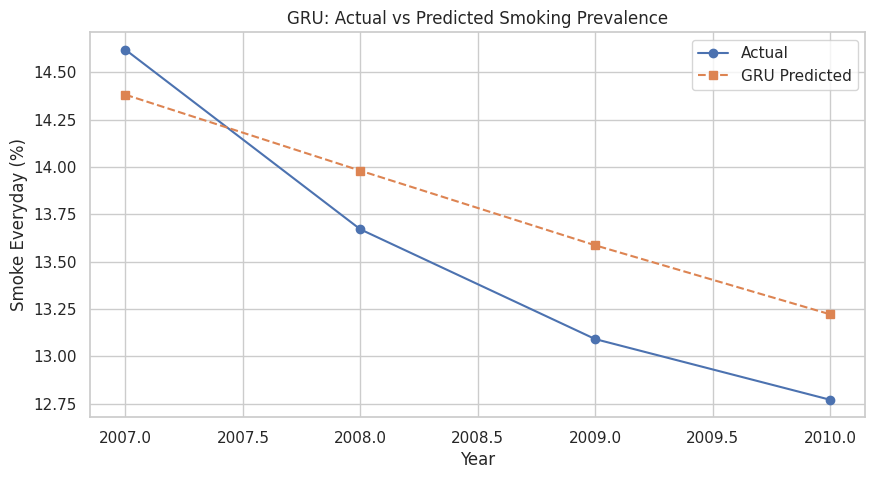

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    gru_annual.index,
    gru_annual["Actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    gru_annual.index,
    gru_annual["Predicted"],
    marker="s",
    linestyle="--",
    label="GRU Predicted"
)

plt.title("GRU: Actual vs Predicted Smoking Prevalence")
plt.xlabel("Year")
plt.ylabel("Smoke Everyday (%)")
plt.legend()
plt.grid(True)
plt.show()


Compare XGBoost, LSTM and GRU


In [ ]:
xgb_compare = (
    xgb_recursive_results[["Year", "State", "Predicted"]]
    .rename(columns={"Predicted": "XGBoost"})
)

lstm_compare = (
    lstm_forecast_results[["Year", "State", "Predicted"]]
    .rename(columns={"Predicted": "LSTM"})
)

gru_compare = (
    gru_forecast_results[["Year", "State", "Predicted"]]
    .rename(columns={"Predicted": "GRU"})
)

common_results = xgb_compare.merge(
    lstm_compare,
    on=["Year", "State"],
    how="inner"
)

common_results = common_results.merge(
    gru_compare,
    on=["Year", "State"],
    how="inner"
)

common_results = common_results.merge(
    lstm_data[["Year", "State", "Smoke everyday"]],
    on=["Year", "State"],
    how="inner"
)

common_annual = (
    common_results.groupby("Year")
    .agg(
        Actual=("Smoke everyday", "mean"),
        XGBoost=("XGBoost", "mean"),
        LSTM=("LSTM", "mean"),
        GRU=("GRU", "mean")
    )
)

comparison_metrics = pd.DataFrame([
    {
        "Model": "XGBoost",
        **metrics(common_annual["Actual"], common_annual["XGBoost"])
    },
    {
        "Model": "LSTM",
        **metrics(common_annual["Actual"], common_annual["LSTM"])
    },
    {
        "Model": "GRU",
        **metrics(common_annual["Actual"], common_annual["GRU"])
    }
])

display(comparison_metrics.sort_values("RMSE"))

,Model,MAE,RMSE,MAPE (%)
2,GRU,0.373418,0.387698,2.801688
0,XGBoost,0.650892,0.759480,4.965355
1,LSTM,0.910907,1.023056,6.920232


Final comparison graph

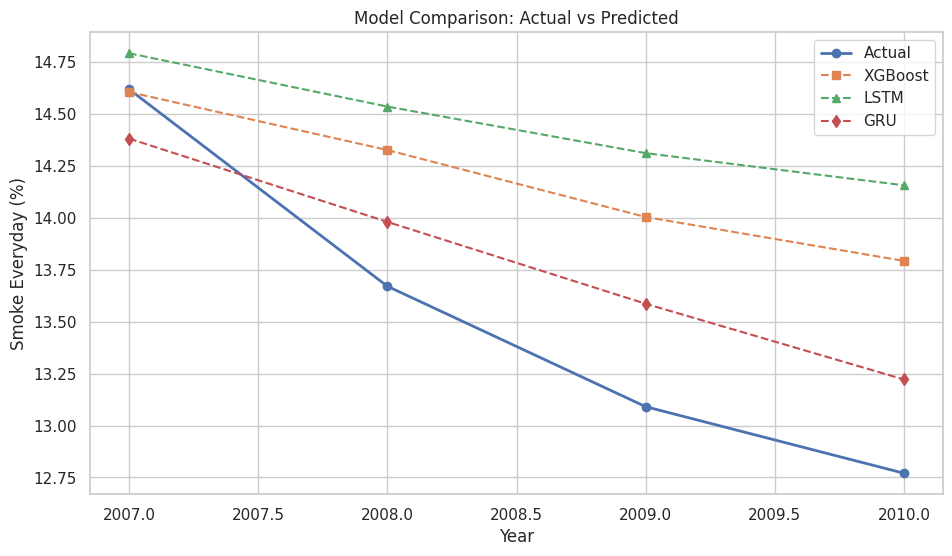

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    common_annual.index,
    common_annual["Actual"],
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    common_annual.index,
    common_annual["XGBoost"],
    marker="s",
    linestyle="--",
    label="XGBoost"
)

plt.plot(
    common_annual.index,
    common_annual["LSTM"],
    marker="^",
    linestyle="--",
    label="LSTM"
)

plt.plot(
    common_annual.index,
    common_annual["GRU"],
    marker="d",
    linestyle="--",
    label="GRU"
)

plt.title("Model Comparison: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Smoke Everyday (%)")
plt.legend()
plt.grid(True)
plt.show()